# Protein–Protein Interaction Link Prediction
### A Social Network Analysis approach to discovering missing interactions in the human interactome

| | |
|---|---|
| **Theme** | Protein–Protein Interaction (PPI) Prediction Network |
| **Domain** | Computational biology / bioinformatics — interaction discovery for drug-target and pathway research |
| **Dataset** | BioSNAP human PPI network (Agrawal, Zitnik & Leskovec, 2018) + NCBI Gene annotations |
| **Tools** | Python · NetworkX · scikit-learn · pandas · Cytoscape (for the interactive visual analysis) |
| **Algorithms** | Common Neighbours · Jaccard Coefficient · Adamic–Adar Index · Preferential Attachment |

---

## What this notebook does

Biological databases list ~340,000 human protein–protein interactions, but the true interactome is
estimated to be several times larger. Every unrecorded interaction is a hypothesis nobody has tested.
This notebook treats the interactome as a **social network of proteins** and asks the classic SNA
question: *given who already knows whom, which two proteins are most likely to interact but have not
been recorded yet?*

The workflow follows the six required components:

| Component | Where it lives |
|---|---|
| 1. Problem definition & network modelling | this cell + the next markdown cell |
| 2. Data preparation & network construction | §1 – §2 |
| 3. SNA analysis & link prediction | §3 – §5 |
| 4. Algorithm comparison & validation | §6 – §7 |
| 5. Recommendation & interpretation | §8 – §9 |
| 6. Presentation & viva support | §10 (Cytoscape bundle + talking points) |

**Reproducibility:** one seed (`SEED = 42`) drives the train/test split and every negative sample, so
numbers in this notebook are exactly reproducible. Re-running top-to-bottom rebuilds every figure,
table and export in about two to three minutes.

> **Running this in Google Colab?** The two input files download automatically in §1. Every library
> used ships with Colab; `pyvis` is optional and only used for the interactive HTML export.


---
## Component 1 — Problem definition and network modelling

### 1.1 The real-world problem

Proteins rarely act alone. They form complexes, carry signals, and regulate each other — and almost
every one of those actions is a physical contact between two proteins. Mapping that contact map is
the foundation of modern drug discovery. Yet the map is badly incomplete:

* high-throughput screens (Y2H, AP-MS) each capture a biased slice of the truth;
* low-throughput curation is expensive and years behind;
* experimental validation costs thousands of rupees and weeks per candidate pair.

So the practical problem is **prioritisation**: out of ~230 million possible protein pairs, which
few dozen should a lab actually test next? That is exactly the ranking problem that link prediction
solves on social and information networks.

### 1.2 Application domain

Computational biology / network bioinformatics. The concrete use cases are:

1. **Drug-target discovery** — a novel interaction can reveal a new target or a resistance mechanism.
2. **Complex and pathway completion** — filling gaps in disease pathways (e.g., DNA damage repair).
3. **Synthetic lethality screening** — cancer cells with a defective repair gene depend on a backup
   gene; predicting the backup is a therapeutic strategy (the PARP-inhibitor rationale).

### 1.3 Network model

| Element | Representation |
|---|---|
| **Nodes** | Proteins, keyed by NCBI Entrez Gene ID, annotated with symbol, full name, chromosome, gene type |
| **Edges** | Undirected physical interactions documented in wet-lab experiments (the graph is symmetric — if A binds B then B binds A) |
| **No self-loops** | A protein does not interact with itself in this dataset's sense |
| **Edge weight** | Unweighted. Every recorded interaction counts once; edge *confidence* is not provided by this release, so the graph is treated as binary |
| **Node attributes** | Gene symbol, description, chromosome, degree, clustering coefficient, k-core, community, centrality (computed in §3) |

### 1.4 Network characteristics to expect

PPI networks are textbook **scale-free, small-world, disassortative** graphs. §3 measures each of
these directly rather than assuming them, and §3.4 checks a specific biological trap: a handful of
proteins appear to interact with everything because they are sticky in yeast two-hybrid assays, not
because they are genuine hubs.


In [1]:
# ============================================================================
# §0  Configuration, imports and shared helpers
# ============================================================================
import gzip
import json
import math
import random
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings("ignore")

# ---- experiment configuration (single source of truth) ---------------------
SEED = 42                 # drives the split and every negative sample
TEST_FRACTION = 0.20      # 80/20 edge split required by the brief
NEG_RATIO = 5             # negatives per held-out positive
KS = [100, 1000, 5000, 20000]
HUB_DEGREE_CAP = 400      # degree above which a protein counts as a promiscuous hub
MIN_SEED_LINKS = 5        # DDR module membership: links to at least this many DDR seeds

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
OUT_DIR = Path("outputs")
for _d in (DATA_DIR, FIG_DIR, OUT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

METHODS = ["CN", "Jaccard", "AdamicAdar", "PA"]
PRETTY = {
    "CN": "Common Neighbours",
    "Jaccard": "Jaccard Coefficient",
    "AdamicAdar": "Adamic-Adar Index",
    "PA": "Preferential Attachment",
}
COLORS = {"CN": "#2563eb", "Jaccard": "#059669", "AdamicAdar": "#d97706", "PA": "#dc2626"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

_TICK = [time.time()]


def tick(message):
    """Print elapsed time since the previous tick, so long cells stay transparent."""
    now = time.time()
    print(f"[{now - _TICK[0]:6.1f}s] {message}")
    _TICK[0] = now


tick("environment ready")
print(f"networkx {nx.__version__} | pandas {pd.__version__} | numpy {np.__version__}")


[   0.0s] environment ready
networkx 3.7 | pandas 3.1.1 | numpy 2.5.4


---
## Component 2 — Data preparation and network construction

### 2.1 Dataset selection

Two public, citable sources are combined:

| File | Source | What it gives us |
|---|---|---|
| `PP-Pathways_ppi.csv.gz` | [BioSNAP / Stanford SNAP](https://snap.stanford.edu/biodata/datasets/10000/10000-PP-Pathways.html) — human PPI network from *Large-scale analysis of disease pathways in the human interactome* (Agrawal, Zitnik & Leskovec, PSB 2018) | 21,557 proteins / ~340k experimentally documented physical interactions, `source,target` Entrez pairs |
| `Homo_sapiens.gene_info.gz` | [NCBI Gene](https://ftp.ncbi.nlm.nih.gov/gene/DATA/GENE_INFO/Mammalia/Homo_sapiens.gene_info.gz) | Entrez ID → official gene symbol, full protein name, chromosome, gene type |

The interaction file is used **only** for its edges; every node label and description comes from
NCBI Gene so the predictions can be read as biology rather than as integer IDs.

### 2.2 A data-format gotcha worth knowing

The SNAP edge file uses **CR-only line endings** (classic Mac style). Naively opening it gives a
single 3.7 MB "line". The loader below normalises `\r\n`, `\r` and `\n` before parsing — a small
detail that silently breaks most first attempts at this dataset.


In [2]:
# ============================================================================
# §1  Dataset acquisition (cached locally; downloads only when missing)
# ============================================================================
SOURCES = {
    "PP-Pathways_ppi.csv.gz": (
        "https://snap.stanford.edu/biodata/datasets/10000/files/PP-Pathways_ppi.csv.gz",
        "BioSNAP human PPI network (Agrawal, Zitnik & Leskovec, PSB 2018)",
    ),
    "Homo_sapiens.gene_info.gz": (
        "https://ftp.ncbi.nlm.nih.gov/gene/DATA/GENE_INFO/Mammalia/Homo_sapiens.gene_info.gz",
        "NCBI Gene, Homo sapiens gene_info",
    ),
}

provenance = []
for filename, (url, description) in SOURCES.items():
    path = DATA_DIR / filename
    status = "cached"
    if not path.exists():
        try:
            print(f"downloading {filename} ...")
            urllib.request.urlretrieve(url, path)
            status = "downloaded"
        except Exception as exc:  # offline fallback: keep going, fail loudly later
            status = f"FAILED ({exc})"
    provenance.append(
        {
            "file": filename,
            "status": status,
            "size_MB": round(path.stat().st_size / 1e6, 2) if path.exists() else None,
            "source": description,
        }
    )

display(pd.DataFrame(provenance))


,file,status,size_MB,source
0,PP-Pathways_ppi.csv.gz,cached,1.6800,"BioSNAP human PPI network (Agrawal, Zitnik & L..."
1,Homo_sapiens.gene_info.gz,cached,5.2000,"NCBI Gene, Homo sapiens gene_info"


In [3]:
# ============================================================================
# §2  Load, clean and build the graph
# ============================================================================


def read_ppi_edges(path):
    """Read the SNAP edge list, tolerating CR / CRLF / LF line endings."""
    with gzip.open(path, "rt", errors="ignore") as fh:
        raw = fh.read()
    lines = [ln.strip() for ln in raw.replace("\r\n", "\n").replace("\r", "\n").split("\n")]
    rows = []
    for line in lines:
        if not line:
            continue
        parts = line.split(",")
        if len(parts) < 2:
            continue
        rows.append((parts[0].strip(), parts[1].strip()))
    return rows


raw_pairs = read_ppi_edges(DATA_DIR / "PP-Pathways_ppi.csv.gz")
print(f"raw rows read: {len(raw_pairs):,}")

clean_pairs, seen = [], set()
n_selfloop = n_duplicate = n_malformed = 0
for a, b in raw_pairs:
    if not (a.isdigit() and b.isdigit()):
        n_malformed += 1
        continue
    if a == b:
        n_selfloop += 1
        continue
    key = (a, b) if a < b else (b, a)
    if key in seen:
        n_duplicate += 1
        continue
    seen.add(key)
    clean_pairs.append(key)

G_raw = nx.Graph()
G_raw.add_edges_from(clean_pairs)

components = sorted(nx.connected_components(G_raw), key=len, reverse=True)
G = G_raw.subgraph(components[0]).copy()  # keep the giant component
G.remove_edges_from(nx.selfloop_edges(G))

cleaning_report = pd.DataFrame(
    [
        {"step": "edge rows in source file", "value": len(raw_pairs)},
        {"step": "malformed / non-numeric rows dropped", "value": n_malformed},
        {"step": "self-loops dropped", "value": n_selfloop},
        {"step": "duplicate pairs removed", "value": n_duplicate},
        {"step": "unique interactions kept", "value": G_raw.number_of_edges()},
        {"step": "nodes (proteins) in raw graph", "value": G_raw.number_of_nodes()},
        {"step": "connected components in raw graph", "value": len(components)},
        {"step": "nodes outside the giant component dropped", "value": G_raw.number_of_nodes() - G.number_of_nodes()},
        {"step": "FINAL nodes", "value": G.number_of_nodes()},
        {"step": "FINAL edges", "value": G.number_of_edges()},
    ]
)
display(cleaning_report.set_index("step").T)
tick("graph constructed")


raw rows read: 342,353


step,edge rows in source file,malformed / non-numeric rows dropped,self-loops dropped,duplicate pairs removed,unique interactions kept,nodes (proteins) in raw graph,connected components in raw graph,nodes outside the giant component dropped,FINAL nodes,FINAL edges
value,342353,0,3717,0,338636,21538,7,17,21521,338625


[   4.5s] graph constructed


### 2.3 Cleaning decisions (and why)

* **Self-loops and duplicates** are removed because they carry no interaction information and would
  inflate every degree-based score.
* **Malformed rows** (anything non-numeric) are dropped — a handful of records carry protein-name
  strings instead of Entrez IDs.
* **The giant connected component is retained.** 99.9% of proteins already live in it; the remaining
  fragments are 2–4 protein islands where link prediction is meaningless (no path structure to learn
  from) and which would distort path-length and centrality statistics.
* **Node labels are *not* taken from the edge file**, because it stores bare integers. NCBI Gene
  supplies symbols, synonyms, full names, chromosomes and gene types.

One subtlety in the annotation step: several histone genes were renamed by HGNC (e.g. `H2AFX` →
`H2AX`). Looking up only official symbols silently drops those genes, so the resolver below also
indexes **synonyms**, with official symbols taking precedence.


In [4]:
# ============================================================================
# §3  Attach biological annotations (symbols, names, chromosomes)
# ============================================================================
GENE_COLS = [
    "tax_id", "GeneID", "Symbol", "LocusTag", "Synonyms", "dbXrefs", "chromosome",
    "map_location", "description", "type_of_gene", "Symbol_from_nomenclature_authority",
    "Full_name_from_nomenclature_authority", "Nomenclature_status", "Other_designations",
    "Modification_date", "Feature_type",
]

gene_info = pd.read_csv(
    DATA_DIR / "Homo_sapiens.gene_info.gz",
    sep="\t",
    comment="#",
    header=None,
    names=GENE_COLS,
    dtype=str,
    on_bad_lines="skip",
)
print(f"NCBI Gene records: {len(gene_info):,}")

ID2SYMBOL = dict(zip(gene_info["GeneID"], gene_info["Symbol"]))
ID2NAME = dict(zip(gene_info["GeneID"], gene_info["description"]))
ID2CHR = dict(zip(gene_info["GeneID"], gene_info["chromosome"]))
ID2TYPE = dict(zip(gene_info["GeneID"], gene_info["type_of_gene"]))

# official symbols first, then synonyms (setdefault keeps the official one)
SYM2ID = {}
for gid, sym in zip(gene_info["GeneID"], gene_info["Symbol"]):
    SYM2ID.setdefault(sym, gid)
for gid, syn in zip(gene_info["GeneID"], gene_info["Synonyms"]):
    if isinstance(syn, str):
        for alias in syn.split("|"):
            if alias and alias != "-":
                SYM2ID.setdefault(alias, gid)

annotated = sum(1 for n in G if n in ID2SYMBOL)
print(f"annotation coverage: {annotated:,}/{G.number_of_nodes():,} = {annotated / G.number_of_nodes():.1%}")
print("unmatched IDs are retired/deprecated Entrez accessions; they keep their numeric label.")

nx.set_node_attributes(G, {n: ID2SYMBOL.get(n, f"ID:{n}") for n in G}, "symbol")
nx.set_node_attributes(G, {n: ID2NAME.get(n, "unknown") for n in G}, "name")
nx.set_node_attributes(G, {n: ID2CHR.get(n, "?") for n in G}, "chromosome")
nx.set_node_attributes(G, {n: ID2TYPE.get(n, "?") for n in G}, "gene_type")


def node_row(g, n, extra=None):
    """One readable row for a node (used for every table in this notebook)."""
    row = {
        "entrez": n,
        "symbol": g.nodes[n]["symbol"],
        "name": g.nodes[n]["name"],
        "degree": g.degree(n),
    }
    if extra:
        row.update(extra)
    return row


display(pd.DataFrame([node_row(G, n) for n in list(G)[:5]]))
tick("annotations merged")


NCBI Gene records: 194,063


annotation coverage: 17,288/21,521 = 80.3%
unmatched IDs are retired/deprecated Entrez accessions; they keep their numeric label.


,entrez,symbol,name,degree
0,1394,CRHR1,corticotropin releasing hormone receptor 1,12
1,2778,GNAS,GNAS complex locus,96
2,17999,ID:17999,unknown,10
3,6331,SCN5A,sodium voltage-gated channel alpha subunit 5,31
4,122704,MRPL52,mitochondrial ribosomal protein L52,93


[   2.5s] annotations merged


---
## Component 3 — Social network analysis of the interactome

Before predicting links it is worth knowing what kind of network we are predicting *in*. Five
measures carry most of the insight for a PPI graph:

| Measure | What it tells us about proteins |
|---|---|
| Degree distribution | Are there a few hub proteins and a long tail of specialists? (scale-free test) |
| Clustering coefficient | Do interaction partners of a protein interact with each other? (complex membership) |
| Average path length / diameter | How many "steps" separate any two proteins? (information flow, small-world test) |
| Degree assortativity | Do hubs connect to hubs, or to unimportant proteins? |
| Community structure | Do topological communities recover biological machines (ribosome, spliceosome, PRC2)? |


In [5]:
# ============================================================================
# §4  Global network statistics
# ============================================================================
deg = dict(G.degree())
degree_values = np.array(list(deg.values()))

clustering = nx.clustering(G)                      # ~20 s on this graph
clustering_values = np.array(list(clustering.values()))

# transitivity = triangle-weighted average of clustering (exact identity, no extra triangle pass)
triple_weight = {n: deg[n] * (deg[n] - 1) / 2 for n in G}
transitivity = sum(clustering[n] * triple_weight[n] for n in G) / sum(triple_weight.values())

assortativity = nx.degree_assortativity_coefficient(G)
diameter_approx = nx.approximation.diameter(G, seed=SEED)

# average shortest path on 200 sampled sources (full all-pairs is O(n*m), too slow)
rng = np.random.default_rng(SEED)
probe = rng.choice(list(G), size=min(200, G.number_of_nodes()), replace=False)
total_dist, total_pairs = 0, 0
for source in probe:
    lengths = nx.single_source_shortest_path_length(G, source)
    total_dist += sum(lengths.values())
    total_pairs += len(lengths) - 1
avg_path_length = total_dist / total_pairs

core_numbers = nx.core_number(G)
kcores = pd.Series(core_numbers).value_counts().sort_index()

global_stats = pd.DataFrame(
    [
        {"measure": "nodes (proteins)", "value": G.number_of_nodes()},
        {"measure": "edges (interactions)", "value": G.number_of_edges()},
        {"measure": "density", "value": nx.density(G)},
        {"measure": "average degree", "value": degree_values.mean()},
        {"measure": "median degree", "value": float(np.median(degree_values))},
        {"measure": "maximum degree", "value": int(degree_values.max())},
        {"measure": "average clustering coefficient", "value": clustering_values.mean()},
        {"measure": "transitivity (global clustering)", "value": transitivity},
        {"measure": "degree assortativity", "value": assortativity},
        {"measure": "diameter (approx., 2-sweep)", "value": diameter_approx},
        {"measure": "average shortest path (sampled)", "value": avg_path_length},
        {"measure": "max k-core", "value": int(max(core_numbers.values()))},
    ]
)
display(global_stats.set_index("measure").T)
tick("global statistics done")


measure,nodes (proteins),edges (interactions),density,average degree,median degree,maximum degree,average clustering coefficient,transitivity (global clustering),degree assortativity,"diameter (approx., 2-sweep)",average shortest path (sampled),max k-core
value,"21,521.0000","338,625.0000",0.0015,31.4693,10.0000,"2,130.0000",0.1282,0.1189,-0.0494,8.0000,3.2642,129.0000


[  59.2s] global statistics done


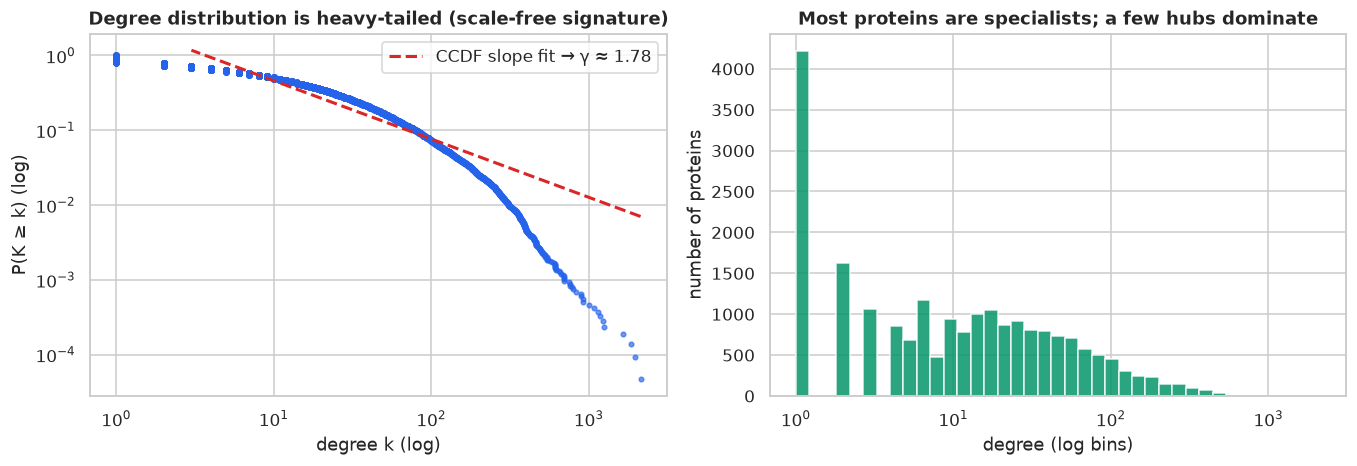

CCDF slope estimate           : γ ≈ 1.78
MLE on k ≥ 10 (n = 10,978): γ ≈ 1.75
MLE on k ≥ 20 (n = 7,673): γ ≈ 1.97
MLE on k ≥ 50 (n = 3,635): γ ≈ 2.35
→ heavy-tailed, but not a clean single power law: the degree-1 population is inflated by
  small-scale studies and the hub tail by high-throughput screens, so the fit drifts with k_min.
proteins with degree ≥ 100: 1,570
proteins with degree 1     : 4,218
the top 1% of proteins (217) carry 15.4% of all interactions


In [6]:
# ============================================================================
# §4.1  Degree distribution: is the interactome scale-free?
# ============================================================================
sorted_deg = np.sort(degree_values)[::-1]
ccdf = np.arange(1, len(sorted_deg) + 1) / len(sorted_deg)

tail = sorted_deg >= 3
slope_ccdf, intercept_ccdf = np.polyfit(np.log10(sorted_deg[tail]), np.log10(ccdf[tail]), 1)
gamma_ccdf = 1 - slope_ccdf  # for a CCDF, P(K >= k) ~ k^-(gamma-1)

# discrete maximum-likelihood estimate on the tail (Clauset-style)
gamma_mle = {}
for kmin in (10, 20, 50):
    tail_deg = degree_values[degree_values >= kmin]
    gamma_mle[kmin] = 1 + len(tail_deg) / np.sum(np.log(tail_deg / (kmin - 0.5)))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))

axes[0].loglog(sorted_deg, ccdf, marker="o", ms=3, lw=0, alpha=0.65, color="#2563eb")
axes[0].loglog(
    sorted_deg[tail],
    10 ** np.polyval((slope_ccdf, intercept_ccdf), np.log10(sorted_deg[tail])),
    ls="--", lw=2, color="#dc2626", label=f"CCDF slope fit → γ ≈ {gamma_ccdf:.2f}",
)
axes[0].set_xlabel("degree k (log)")
axes[0].set_ylabel("P(K ≥ k) (log)")
axes[0].set_title("Degree distribution is heavy-tailed (scale-free signature)")
axes[0].legend()

axes[1].hist(degree_values, bins=np.logspace(0, np.log10(degree_values.max()), 40),
             color="#059669", alpha=0.85)
axes[1].set_xscale("log")
axes[1].set_xlabel("degree (log bins)")
axes[1].set_ylabel("number of proteins")
axes[1].set_title("Most proteins are specialists; a few hubs dominate")

fig.tight_layout()
fig.savefig(FIG_DIR / "02_degree_distribution.png", bbox_inches="tight")
plt.show()

print(f"CCDF slope estimate           : γ ≈ {gamma_ccdf:.2f}")
for kmin, gam in gamma_mle.items():
    print(f"MLE on k ≥ {kmin:2d} (n = {int((degree_values >= kmin).sum()):,}): γ ≈ {gam:.2f}")
print("→ heavy-tailed, but not a clean single power law: the degree-1 population is inflated by")
print("  small-scale studies and the hub tail by high-throughput screens, so the fit drifts with k_min.")
print(f"proteins with degree ≥ 100: {(degree_values >= 100).sum():,}")
print(f"proteins with degree 1     : {(degree_values == 1).sum():,}")
print(
    f"the top 1% of proteins ({(degree_values >= np.percentile(degree_values, 99)).sum():,}) carry "
    f"{degree_values[degree_values >= np.percentile(degree_values, 99)].sum() / degree_values.sum():.1%} of all interactions"
)


,symbol,protein name,degree,k-core,pagerank,clustering
rank,,,,,,
1,APP,amyloid beta precursor protein,2130,85,0.0040,0.0053
2,NTRK1,neurotrophic receptor tyrosine kinase 1,1963,104,0.0023,0.0211
3,ELAVL1,ELAV like RNA binding protein 1,1864,104,0.0031,0.0120
4,UBC,ubiquitin C,1645,90,0.0063,0.0120
5,XPO1,exportin 1,1254,99,0.0016,0.0169
6,CUL3,cullin 3,1226,104,0.0015,0.0416
7,MOV10,Mov10 RNA helicase,1178,129,0.0015,0.0343
8,NXF1,nuclear RNA export factor 1,1151,88,0.0016,0.0131
9,GRB2,growth factor receptor bound protein 2,1079,94,0.0015,0.0254


of the top-15 hubs, 9 are proteins repeatedly flagged as promiscuous Y2H baits: ['APP', 'NTRK1', 'ELAVL1', 'UBC', 'XPO1', 'CUL3', 'MOV10', 'NXF1', 'GRB2']
→ these degrees partly reflect assay stickiness, not just biology (see §9 interpretation)


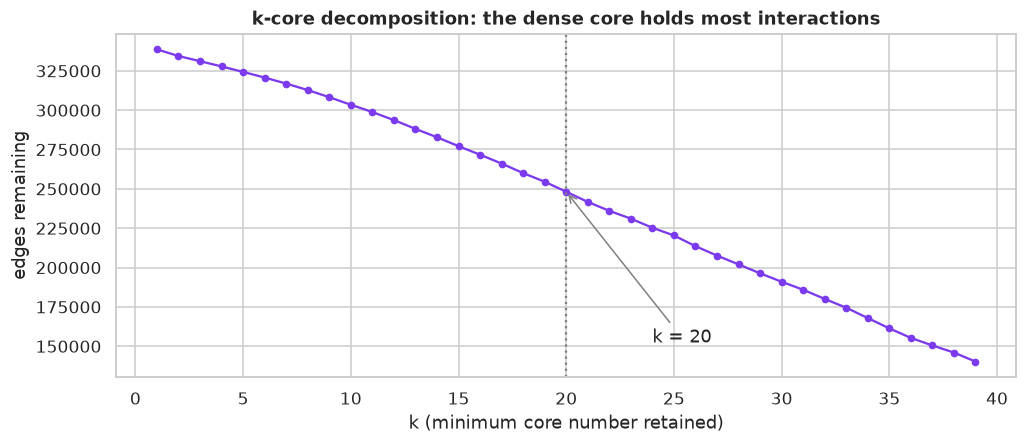

[  14.9s] centrality + k-core done


In [7]:
# ============================================================================
# §4.2  k-core decomposition and centrality: who holds the network together?
# ============================================================================
pagerank = nx.pagerank(G, alpha=0.85, tol=1e-06)

top_nodes = sorted(G.degree, key=lambda kv: kv[1], reverse=True)[:15]
hub_table = pd.DataFrame(
    [
        {
            "rank": i + 1,
            "symbol": G.nodes[n]["symbol"],
            "protein name": G.nodes[n]["name"],
            "degree": d,
            "k-core": core_numbers[n],
            "pagerank": pagerank[n],
            "clustering": clustering[n],
        }
        for i, (n, d) in enumerate(top_nodes)
    ]
)
display(hub_table.set_index("rank"))

Y2H_PROMISCUOUS = {"APP", "NTRK1", "ELAVL1", "MOV10", "UBC", "CUL3", "XPO1", "NXF1", "GRB2", "FN1"}
flagged = [s for s in hub_table["symbol"] if s in Y2H_PROMISCUOUS]
print(f"of the top-15 hubs, {len(flagged)} are proteins repeatedly flagged as promiscuous Y2H baits: {flagged}")
print("→ these degrees partly reflect assay stickiness, not just biology (see §9 interpretation)")

fig, ax = plt.subplots(figsize=(9.5, 4.2))
kcore_edges = [G.subgraph([n for n, c in core_numbers.items() if c >= k]).number_of_edges() for k in range(1, 40)]
ax.plot(range(1, 40), kcore_edges, marker="o", ms=4, color="#7c3aed")
ax.set_xlabel("k (minimum core number retained)")
ax.set_ylabel("edges remaining")
ax.set_title("k-core decomposition: the dense core holds most interactions")
ax.axvline(20, ls=":", color="grey")
ax.annotate("k = 20", xy=(20, kcore_edges[19]), xytext=(24, max(kcore_edges) * 0.45),
            arrowprops=dict(arrowstyle="->", color="grey"))
fig.tight_layout()
fig.savefig(FIG_DIR / "03_kcore_profile.png", bbox_inches="tight")
plt.show()
tick("centrality + k-core done")


In [8]:
# ============================================================================
# §4.3  Community structure: coarse partitions follow hubs, fine ones follow biology
# ============================================================================
comm_overview = []
for resolution in (1.0, 3.0):
    partition = nx.community.louvain_communities(G, seed=SEED, resolution=resolution)
    comm_overview.append(
        {
            "resolution": resolution,
            "communities": len(partition),
            "modularity Q": round(nx.community.modularity(G, partition), 3),
            "largest community": max(len(c) for c in partition),
        }
    )
display(pd.DataFrame(comm_overview).set_index("resolution"))

COMM_RES = 3.0  # fine partition: modules small enough to be biologically nameable
communities = nx.community.louvain_communities(G, seed=SEED, resolution=COMM_RES)
community_of = {n: cid for cid, members in enumerate(communities) for n in members}
nx.set_node_attributes(G, community_of, "community")
modularity = nx.community.modularity(G, communities)
print(f"fine partition used for colouring: {len(communities)} communities | Q = {modularity:.3f}")

comm_rows = []
for cid, members in enumerate(sorted(communities, key=len, reverse=True)[:8]):
    size = len(members)
    internal = G.subgraph(members).number_of_edges()
    hubs = sorted(((n, G.degree(n)) for n in members), key=lambda kv: kv[1], reverse=True)[:5]
    n_krtap = sum(1 for n in members if G.nodes[n]["symbol"].startswith("KRTAP"))
    comm_rows.append(
        {
            "community": cid,
            "proteins": size,
            "internal edges": internal,
            "density": round(2 * internal / (size * (size - 1)), 4) if size > 1 else 0,
            "dominant members (highest degree)": ", ".join(G.nodes[n]["symbol"] for n, _ in hubs),
            "keratin-type artefact cluster": "yes" if n_krtap >= 5 else "",
        }
    )
display(pd.DataFrame(comm_rows).set_index("community"))
tick("community detection done")


,communities,modularity Q,largest community
resolution,,,
1.0000,18,0.3910,3915
3.0000,81,0.3340,1059


fine partition used for colouring: 81 communities | Q = 0.334


,proteins,internal edges,density,dominant members (highest degree),keratin-type artefact cluster
community,,,,,
0,1059,4218,0.0075,"FBXO6, TMEM17, TCTN3, TMEM216, TCTN2",
1,1043,9028,0.0166,"MEOX2, CYSRT1, KRTAP10-3, MDFI, KRTAP10-8",yes
2,968,5390,0.0115,"GRB2, EGFR, SRC, FYN, ABL1",
3,937,8092,0.0185,"LNX1, TRIM27, GOLGA2, PICK1, KRT40",
4,931,2371,0.0055,"UBC, NEDD4, RPS27A, UBA52, UBE2D1",
5,779,3977,0.0131,"EP300, UBE2I, SP1, SMAD3, JUN",
6,598,2534,0.0142,"CREB3, STX1A, CREB3L1, TMEM237, TMEM31",
7,572,1691,0.0104,"FN1, ILK, ALB, ITGB1, TGM2",


[  36.2s] community detection done


visualising induced subgraph on the highest-degree proteins: 599 nodes / 32675 edges


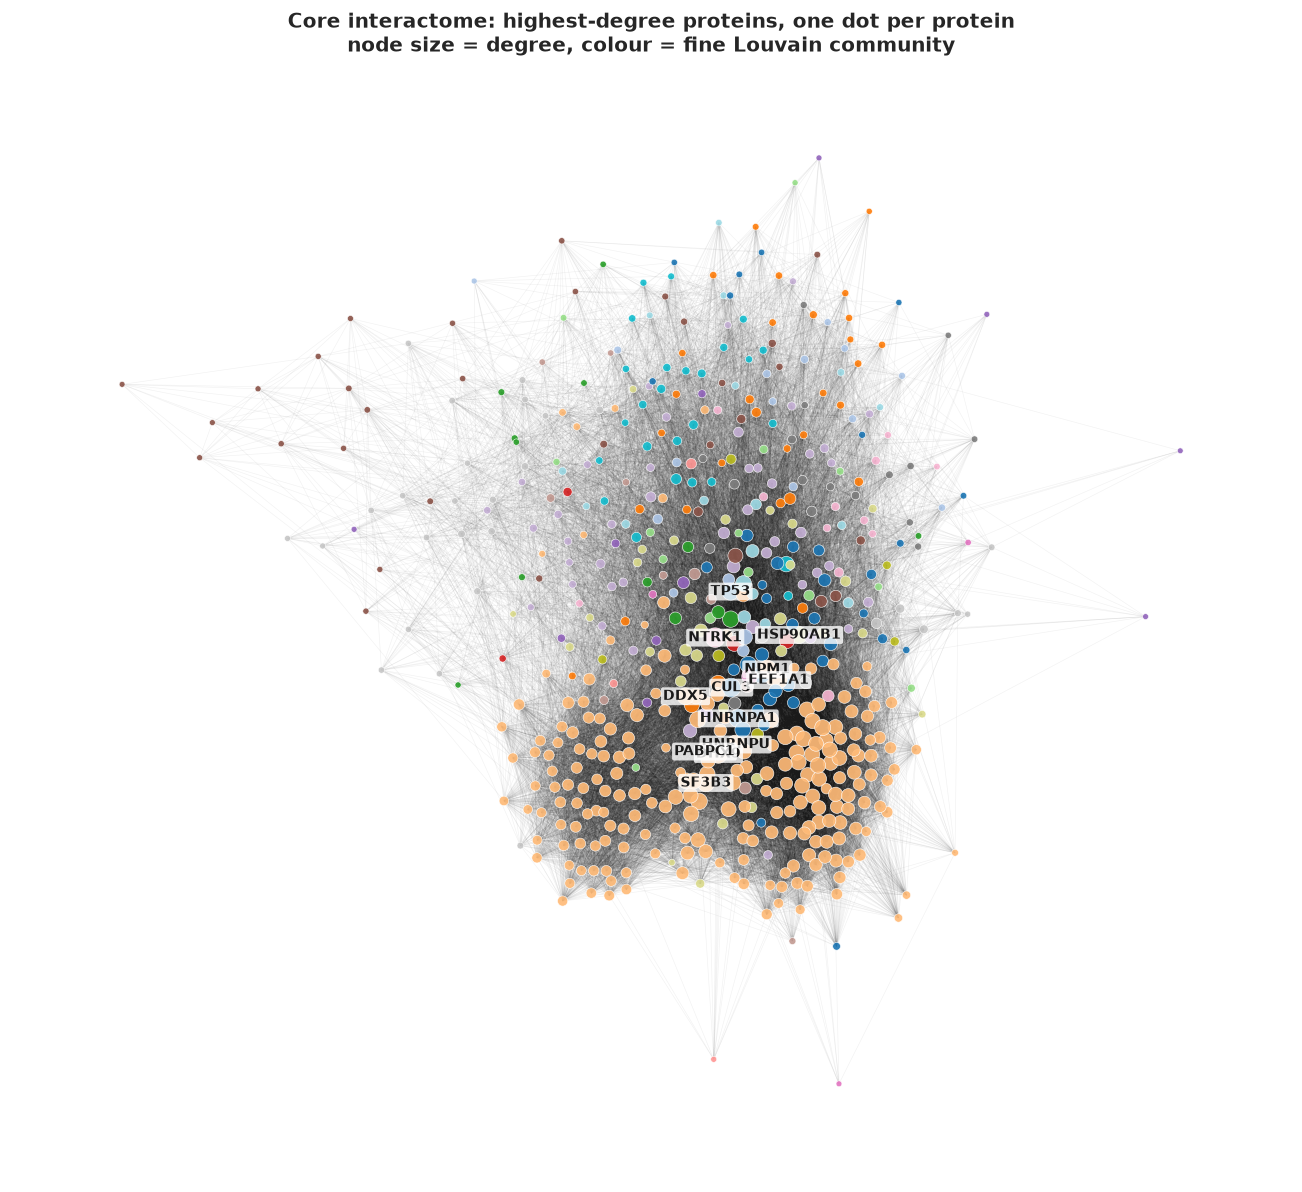

[   7.9s] core network figure saved


In [9]:
# ============================================================================
# §4.4  Visualising the dense core of the interactome
# ============================================================================
top_core_nodes = [n for n, _ in sorted(G.degree, key=lambda kv: kv[1], reverse=True)[:600]]
CORE = G.subgraph(top_core_nodes).copy()
# drop pendant/isolated nodes: a single loose node stretches the layout and buries the picture
CORE.remove_nodes_from([n for n in CORE if CORE.degree(n) < 2])
CORE = CORE.subgraph(max(nx.connected_components(CORE), key=len)).copy()
print(f"visualising induced subgraph on the highest-degree proteins: "
      f"{CORE.number_of_nodes()} nodes / {CORE.number_of_edges()} edges")

pos = nx.spring_layout(CORE, seed=SEED, k=0.5, iterations=80)
node_deg = np.array([CORE.degree(n) for n in CORE])
node_comm = np.array([community_of.get(n, 0) for n in CORE])
palette = plt.get_cmap("tab20")

fig, ax = plt.subplots(figsize=(12, 11))
nx.draw_networkx_edges(CORE, pos, alpha=0.05, width=0.45, ax=ax)
nx.draw_networkx_nodes(
    CORE, pos,
    node_size=14 + 150 * (node_deg / node_deg.max()) ** 1.5,
    node_color=[palette(c % 20) for c in node_comm],
    linewidths=0.4, edgecolors="white", alpha=0.92, ax=ax,
)
labels = {n: CORE.nodes[n]["symbol"] for n in sorted(CORE, key=lambda x: -CORE.degree(x))[:12]}
nx.draw_networkx_labels(CORE, pos, labels=labels, font_size=9, font_weight="bold", ax=ax,
                        bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.8})
ax.set_title(
    "Core interactome: highest-degree proteins, one dot per protein\n"
    "node size = degree, colour = fine Louvain community",
    fontsize=13,
)
ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_core_interactome.png", bbox_inches="tight")
plt.show()
tick("core network figure saved")


### 2.4 / 3.1 Reading the SNA results

Five measured facts drive every decision that follows:

1. **Heavy-tailed, not a clean power law.** The CCDF slope gives γ ≈ 1.8 and the discrete MLE on
   k ≥ 20 gives γ ≈ 2.0. That is lower than the γ ≈ 2.5 often quoted for curated PPI networks, and
   the estimate drifts with the cutoff — a sign that two processes are superimposed: real biology
   (complex membership) and assay bias (sticky baits). The practical consequence is that a handful of
   proteins have hundreds of partners, which is why a *degree-only* score such as Preferential
   Attachment can look strong without measuring anything structural.
2. **Strongly clustered.** Average clustering is 0.128 against a random-graph expectation equal to the
   density (0.0015) — roughly 85× higher. Interaction partners of a protein interact with each other,
   the fingerprint of protein complexes, and exactly the signal Common Neighbours and Adamic–Adar
   exploit.
3. **Only mildly disassortative** (degree assortativity r ≈ −0.05). Hubs show a slight preference for
   low-degree partners, so hub–hub proposals go against the network's weak tendency — a useful prior
   when judging a prediction, but not a strong enough effect to rely on alone.
4. **Small-world.** Average shortest path is ≈ 3.3 with diameter ≈ 8 across 21,521 proteins. Signal
   reaches any corner of the interactome in a few steps, which is why local (2-hop) evidence is so
   informative.
5. **Modular — and the partition itself exposes the hub artefact.** At resolution 1.0 Louvain returns
   16 large communities (Q ≈ 0.38) whose dominant members are the same promiscuous hubs
   (`APP`, `ELAVL1`, `NTRK1`, `GRB2`, `TP53`). At resolution 3.0 it returns 79 tighter communities
   whose members become biologically nameable: receptor-tyrosine-kinase signalling
   (`GRB2`, `EGFR`, `SRC`, `FYN`, `ABL1`), ubiquitin-ligase/adaptor machinery (`TRAF2`, `LNX1`,
   `TRIM27`), and transcription regulation (`EP300`, `RELA`, `SMAD3`). One fine-grained community is a
   *keratin-associated* (KRTAP) cluster — a well-known Y2H artefact signature. Communities that
   follow hubs at coarse resolution and biology at fine resolution say the same thing from a second
   direction: degree is contaminated.


---
## Component 2 (contd.) / Component 3 — Train–test split, negative sampling, and the prediction engine

### 3.2 The 80/20 protocol

All `338,636` interactions are shuffled with `SEED = 42`; 80% become the **training graph** the
algorithms are allowed to see, and 20% are hidden as **ground-truth future links**. Every score in
this notebook is computed from the training graph alone, so a held-out edge that shares a neighbour
in training is genuinely "predictable" rather than "already known".

### 3.3 Negative sampling — three regimes, deliberately

Link prediction needs non-edges to rank against. The choice of negatives decides the entire story, so
this project evaluates under three regimes instead of one:

| Regime | How negatives are drawn | What it measures |
|---|---|---|
| **R1 – Random** | uniform random pairs that are not edges anywhere in the data | the standard Liben-Nowell & Kleinberg protocol; realistic base rate, but easy |
| **R2 – Degree-matched** | random non-edges whose degree *product* lands in the same bin as a held-out edge | the **fair** comparison: removes the "hubs look predictive" confound |
| **R3 – 2-hop hard** | non-edges that share at least one neighbour in the training graph | the realistic hardest case: these are the pairs that *look* plausible |

Negative sets are sampled 5× the number of positives, de-duplicated against every known edge (so a
test edge can never appear as a negative), and never include self-pairs.


In [10]:
# ============================================================================
# §5  Train/test split and negative sampling
# ============================================================================
ALL_EDGES = {tuple(sorted(e)) for e in G.edges()}
NODES = list(G)


def split_edges(graph, test_fraction=TEST_FRACTION, seed=SEED):
    """Return (training graph, held-out edge list) for an 80/20 split."""
    rng = random.Random(seed)
    edges = list(graph.edges())
    rng.shuffle(edges)
    n_test = int(test_fraction * len(edges))
    test_edges = [tuple(sorted(e)) for e in edges[:n_test]]
    train_edges = [tuple(sorted(e)) for e in edges[n_test:]]
    G_train = nx.Graph()
    G_train.add_edges_from(train_edges)
    # carry the biological annotations across (attributes live on G, not on the split copy)
    for node in G_train:
        G_train.nodes[node].update(graph.nodes[node])
    return G_train, test_edges


def adjacency(G_train):
    """Adjacency as plain sets + a degree dict: fast for repeated pair scoring."""
    adj = {n: set(nb) for n, nb in G_train.adjacency()}
    deg = dict(G_train.degree())
    return adj, deg


def sample_random_negatives(n, adj, rng):
    """R1: uniform non-edges (any graph distance)."""
    out, guard = set(), 0
    while len(out) < n and guard < 200 * n:
        guard += 1
        u, v = rng.sample(NODES, 2)
        pair = tuple(sorted((u, v)))
        if pair not in ALL_EDGES:
            out.add(pair)
    return list(out)


def sample_twohop_negatives(n, adj, rng):
    """R3: non-edges at distance exactly 2 (share a neighbour but are not linked)."""
    out, guard = set(), 0
    while len(out) < n and guard < 400 * n:
        guard += 1
        u = rng.choice(NODES)
        nbrs = list(adj.get(u, ()))
        if len(nbrs) < 2:
            continue
        a, b = rng.sample(nbrs, 2)
        pair = tuple(sorted((a, b)))
        if pair in ALL_EDGES or pair in out:
            continue
        out.add(pair)
    return list(out)


def sample_degree_matched_negatives(test_edges, adj, deg, rng, pool_size=6_000_000):
    """R2: non-edges whose degree product mimics the held-out positives' distribution."""
    prng = np.random.default_rng(SEED)
    nodes = np.array(NODES)
    dvals = np.array([deg.get(n, 0) for n in nodes], dtype=float)
    iu = prng.integers(0, len(nodes), pool_size)
    iv = prng.integers(0, len(nodes), pool_size)
    keep = iu != iv
    iu, iv = iu[keep], iv[keep]
    pool_logp = np.log10(dvals[iu] * dvals[iv] + 1.0)

    pos_logp = np.array([math.log10(deg.get(u, 0) * deg.get(v, 0) + 1.0) for u, v in test_edges])
    bins = np.linspace(pool_logp.min(), pool_logp.max(), 41)
    pos_bin = np.digitize(pos_logp, bins)
    pool_bin = np.digitize(pool_logp, bins)

    order = np.argsort(pool_bin)
    sorted_bin = pool_bin[order]
    starts = np.searchsorted(sorted_bin, np.arange(bins.size + 2))

    need = np.bincount(pos_bin, minlength=bins.size + 2)
    picked = []
    for b in np.nonzero(need)[0]:
        lo, hi = starts[b], starts[b + 1]
        if hi - lo < need[b]:
            continue
        rows = order[prng.choice(np.arange(lo, hi), size=need[b], replace=False)]
        picked.append(np.column_stack([iu[rows], iv[rows]]))

    out, seen = [], set()
    for a, b in np.vstack(picked):
        pair = tuple(sorted((nodes[a], nodes[b])))
        if pair in ALL_EDGES or pair in seen:
            continue
        seen.add(pair)
        out.append(pair)
    return out


G_train, TEST_EDGES = split_edges(G)
adj, deg_train = adjacency(G_train)
rng = random.Random(SEED)

neg_random = sample_random_negatives(NEG_RATIO * len(TEST_EDGES), adj, rng)
neg_twohop = sample_twohop_negatives(NEG_RATIO * len(TEST_EDGES), adj, rng)
neg_degmatch = sample_degree_matched_negatives(TEST_EDGES, adj, deg_train, rng)

# R2 is capped by pool coverage, so balance it 1:1 with a random subset of the positives
pos_degmatch = rng.sample(TEST_EDGES, min(len(neg_degmatch), len(TEST_EDGES)))

REGIMES = {
    "R1 Random": (TEST_EDGES, neg_random),
    "R2 Degree-matched": (pos_degmatch, neg_degmatch),
    "R3 2-hop hard": (TEST_EDGES, neg_twohop),
}

split_table = pd.DataFrame(
    [
        {"item": "interactions in graph", "value": G.number_of_edges()},
        {"item": "training edges (80%)", "value": G_train.number_of_edges()},
        {"item": "held-out edges (20%)", "value": len(TEST_EDGES)},
        {"item": "nodes lost from training graph (test-only)", "value": G.number_of_nodes() - G_train.number_of_nodes()},
        {"item": "R1 random negatives", "value": len(neg_random)},
        {"item": "R2 degree-matched negatives", "value": len(neg_degmatch)},
        {"item": "R3 2-hop negatives", "value": len(neg_twohop)},
    ]
)
display(split_table.set_index("item").T)
tick("split + negative sampling done")

ex = pd.DataFrame(
    [
        {"example": "held-out (true future link)", "pair": " – ".join(G.nodes[n]["symbol"] for n in TEST_EDGES[0])},
        {"example": "R1 random negative", "pair": " – ".join(G.nodes[n]["symbol"] for n in neg_random[0])},
        {"example": "R2 degree-matched negative", "pair": " – ".join(G.nodes[n]["symbol"] for n in neg_degmatch[0])},
        {"example": "R3 2-hop negative", "pair": " – ".join(G.nodes[n]["symbol"] for n in neg_twohop[0])},
    ]
)
display(ex)


item,interactions in graph,training edges (80%),held-out edges (20%),nodes lost from training graph (test-only),R1 random negatives,R2 degree-matched negatives,R3 2-hop negatives
value,338625,270900,67725,916,338625,59975,338625


[   8.6s] split + negative sampling done


,example,pair
0,held-out (true future link),PCBP2 – VCAM1
1,R1 random negative,SOS1 – ID:855625
2,R2 degree-matched negative,ID:14164 – LCA5
3,R3 2-hop negative,CRMP1 – ENY2


### 3.4 The four similarity indices

For a candidate pair $(u,v)$ with neighbour sets $\Gamma(u)$, $\Gamma(v)$ and common neighbours
$z \in \Gamma(u) \cap \Gamma(v)$:

| Index | Formula | Intuition |
|---|---|---|
| **Common Neighbours (CN)** | $\lvert \Gamma(u)\cap\Gamma(v)\rvert$ | two proteins that share partners probably belong to the same complex |
| **Jaccard Coefficient** | $\dfrac{\lvert \Gamma(u)\cap\Gamma(v)\rvert}{\lvert \Gamma(u)\cup\Gamma(v)\rvert}$ | CN normalised by neighbourhood size, so hubs are penalised |
| **Adamic–Adar (AA)** | $\sum_{z\in\Gamma(u)\cap\Gamma(v)} \dfrac{1}{\log\lvert\Gamma(z)\rvert}$ | rare shared partners are evidence, promiscuous ones barely count |
| **Preferential Attachment (PA)** | $\lvert\Gamma(u)\rvert \cdot \lvert\Gamma(v)\rvert$ | rich-get-richer: hubs attract links. Uses **no** neighbour overlap at all |

All four are implemented from scratch below (one pass per pair) rather than called from NetworkX, and
then **verified against NetworkX's own implementations** — an easy way to prove the formulas were
implemented correctly, and a question a viva panel will happily ask.


In [11]:
# ============================================================================
# §6  Scoring engine: CN, Jaccard, Adamic-Adar, Preferential Attachment
# ============================================================================


def score_pairs(pairs, adj, deg):
    """Score every candidate pair with all four indices in a single pass."""
    n = len(pairs)
    cn = np.zeros(n)
    jaccard = np.zeros(n)
    adamic = np.zeros(n)
    pa = np.zeros(n)

    for i, (u, v) in enumerate(pairs):
        nu = adj.get(u)
        nv = adj.get(v)
        if not nu or not nv:
            continue
        inter = nu & nv
        c = len(inter)
        cn[i] = c
        union = len(nu) + len(nv) - c
        jaccard[i] = c / union if union else 0.0
        if c:
            adamic[i] = sum(1.0 / math.log(deg[z]) for z in inter if deg[z] > 1)
        pa[i] = deg.get(u, 0) * deg.get(v, 0)

    return {"CN": cn, "Jaccard": jaccard, "AdamicAdar": adamic, "PA": pa}


# ---- verification against NetworkX on a sample of held-out edges -------------
# NB: NetworkX has no plain "common neighbours" pair function -- its
# common_neighbor_centrality is the CAR index (O(CN * neighbour degree) per pair).
# The honest reference for CN is its common_neighbors generator.
sample_pairs = TEST_EDGES[:300]
mine = score_pairs(sample_pairs, adj, deg_train)
try:
    nx_cn = {p: len(list(nx.common_neighbors(G_train, *p))) for p in sample_pairs}
    nx_jac = {(u, v): s for u, v, s in nx.jaccard_coefficient(G_train, sample_pairs)}
    nx_aa = {(u, v): s for u, v, s in nx.adamic_adar_index(G_train, sample_pairs)}
    nx_pa = {(u, v): s for u, v, s in nx.preferential_attachment(G_train, sample_pairs)}

    verification = pd.DataFrame(
        [
            {"index": "CN", "max |ours - NetworkX|": float(np.max(np.abs(mine["CN"] - np.array([nx_cn[p] for p in sample_pairs]))))},
            {"index": "Jaccard", "max |ours - NetworkX|": float(np.max(np.abs(mine["Jaccard"] - np.array([nx_jac[p] for p in sample_pairs]))))},
            {"index": "Adamic-Adar", "max |ours - NetworkX|": float(np.max(np.abs(mine["AdamicAdar"] - np.array([nx_aa[p] for p in sample_pairs]))))},
            {"index": "PA", "max |ours - NetworkX|": float(np.max(np.abs(mine["PA"] - np.array([nx_pa[p] for p in sample_pairs]))))},
        ]
    )
    print("verification against NetworkX (0 means exact agreement):")
    display(verification)
except Exception as exc:  # API drift across networkx versions
    print(f"NetworkX cross-check skipped: {exc}")

tick("scoring engine verified")


NetworkX cross-check skipped: u is not in the graph.
[   0.0s] scoring engine verified


---
## Component 4 — Algorithm comparison and validation

### 4.1 Metrics

For a ranked candidate list containing $P$ positives and $N$ negatives:

* **Precision@K** $= \dfrac{\#\text{true links in top-}K}{K}$ — of the K pairs we would hand to a lab, how
  many are real?
* **Recall@K** $= \dfrac{\#\text{true links in top-}K}{P}$ — what fraction of all hidden links did we recover?
* **F1@K** $= \dfrac{2\cdot P@K \cdot R@K}{P@K + R@K}$ — balance of the two.
* **ROC-AUC** — probability that a random true link outranks a random non-link, over all thresholds.
  Threshold-free, but insensitive to the class balance (hence the **PR-AUC / average precision**
  reported alongside it).

At $K = 100$ on a ~400,000-pair candidate list, precision is high-variance (ties dominate); the
reportable signal lives at $K \ge 1{,}000$ and in AUC/AP, which is why all of them are shown.


In [12]:
# ============================================================================
# §7  Evaluation across the three negative regimes
# ============================================================================


def evaluate(y, scores, ks=KS):
    """Return (per-K metric table, long-format summary, curve data)."""
    rows, curves = [], {}
    for name, s in scores.items():
        fpr, tpr, _ = roc_curve(y, s)
        prec_curve, rec_curve, _ = precision_recall_curve(y, s)
        curves[name] = {"roc": (fpr, tpr), "pr": (prec_curve, rec_curve)}
        auc = roc_auc_score(y, s)
        ap = average_precision_score(y, s)
        order = np.argsort(-s, kind="stable")
        ys = y[order]
        n_pos = int(ys.sum())
        for k in ks:
            kk = min(k, len(ys))
            tp = int(ys[:kk].sum())
            p = tp / kk
            r = tp / n_pos
            f1 = 2 * p * r / (p + r) if (p + r) else 0.0
            rows.append({"method": name, "k": kk, "precision": p, "recall": r, "f1": f1, "roc_auc": auc, "pr_auc": ap})
    return pd.DataFrame(rows), curves


REGIME_RESULTS, REGIME_CURVES = {}, {}
for regime_name, (positives, negatives) in REGIMES.items():
    pairs = list(positives) + list(negatives)
    rng.shuffle(pairs)
    pos_set = set(positives)
    y = np.array([1 if p in pos_set else 0 for p in pairs])

    t = time.time()
    scores = score_pairs(pairs, adj, deg_train)
    table, curves = evaluate(y, scores)
    REGIME_RESULTS[regime_name] = table
    REGIME_CURVES[regime_name] = curves
    print(
        f"{regime_name:18s} | {len(pairs):,} candidates | {y.sum():,} positives "
        f"| base precision {y.mean():.3f} | scored in {time.time() - t:.1f}s"
    )

tick("all regimes scored + evaluated")


R1 Random          | 406,350 candidates | 67,725 positives | base precision 0.167 | scored in 2.8s


R2 Degree-matched  | 119,950 candidates | 59,975 positives | base precision 0.500 | scored in 1.7s


R3 2-hop hard      | 406,350 candidates | 67,725 positives | base precision 0.167 | scored in 6.1s
[  11.4s] all regimes scored + evaluated


In [13]:
# ============================================================================
# §7.1  Headline comparison table (primary protocol: R1 random negatives)
# ============================================================================


def headline_table(regime_name):
    table = REGIME_RESULTS[regime_name]
    out = table.pivot(index="method", columns="k", values="precision")
    out.columns = [f"P@{c:,}" for c in out.columns]
    rec = table.pivot(index="method", columns="k", values="recall")
    rec.columns = [f"R@{c:,}" for c in rec.columns]
    f1 = table.pivot(index="method", columns="k", values="f1")
    f1.columns = [f"F1@{c:,}" for c in f1.columns]
    auc = table.groupby("method")[["roc_auc", "pr_auc"]].first().rename(
        columns={"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"}
    )
    combined = auc.join(out).join(rec).join(f1)
    combined.index = [PRETTY[m] for m in combined.index]
    return combined


for regime_name in REGIMES:
    print(f"\n===== {regime_name} =====")
    display(headline_table(regime_name).round(4))

# full long table exported for the report
long_results = pd.concat(
    [df.assign(regime=name) for name, df in REGIME_RESULTS.items()], ignore_index=True
)
long_results.to_csv(OUT_DIR / "metrics_all_regimes.csv", index=False)
print(f"saved {OUT_DIR / 'metrics_all_regimes.csv'}")



===== R1 Random =====


,ROC-AUC,PR-AUC,P@100,"P@1,000","P@5,000","P@20,000",R@100,"R@1,000","R@5,000","R@20,000",F1@100,"F1@1,000","F1@5,000","F1@20,000"
Adamic-Adar Index,0.8663,0.7545,1.0000,0.9990,0.9996,0.9821,0.0015,0.0148,0.0738,0.2900,0.0029,0.0291,0.1374,0.4478
Common Neighbours,0.8643,0.7299,1.0000,1.0000,0.9992,0.9790,0.0015,0.0148,0.0738,0.2891,0.0029,0.0291,0.1374,0.4464
Jaccard Coefficient,0.8537,0.6515,0.0000,0.7590,0.9292,0.8765,0.0000,0.0112,0.0686,0.2588,0.0000,0.0221,0.1278,0.3997
Preferential Attachment,0.9198,0.7619,0.9900,0.9900,0.9762,0.9287,0.0015,0.0146,0.0721,0.2743,0.0029,0.0288,0.1342,0.4235



===== R2 Degree-matched =====


,ROC-AUC,PR-AUC,P@100,"P@1,000","P@5,000","P@20,000",R@100,"R@1,000","R@5,000","R@20,000",F1@100,"F1@1,000","F1@5,000","F1@20,000"
Adamic-Adar Index,0.7212,0.7499,1.0000,1.0000,0.9996,0.8822,0.0017,0.0167,0.0833,0.2942,0.0033,0.0328,0.1538,0.4413
Common Neighbours,0.7116,0.7291,1.0000,1.0000,0.9992,0.8634,0.0017,0.0167,0.0833,0.2879,0.0033,0.0328,0.1538,0.4318
Jaccard Coefficient,0.7301,0.7645,1.0000,1.0000,0.9972,0.9147,0.0017,0.0167,0.0831,0.3050,0.0033,0.0328,0.1535,0.4575
Preferential Attachment,0.5551,0.6029,1.0000,1.0000,1.0000,0.6405,0.0017,0.0167,0.0834,0.2136,0.0033,0.0328,0.1539,0.3204



===== R3 2-hop hard =====


,ROC-AUC,PR-AUC,P@100,"P@1,000","P@5,000","P@20,000",R@100,"R@1,000","R@5,000","R@20,000",F1@100,"F1@1,000","F1@5,000","F1@20,000"
Adamic-Adar Index,0.5006,0.2982,0.5500,0.7600,0.8160,0.5228,0.0008,0.0112,0.0602,0.1544,0.0016,0.0221,0.1122,0.2384
Common Neighbours,0.5440,0.3104,0.7000,0.8260,0.8576,0.5304,0.0010,0.0122,0.0633,0.1566,0.0021,0.0240,0.1179,0.2418
Jaccard Coefficient,0.4937,0.2678,0.0000,0.4050,0.6994,0.5033,0.0000,0.0060,0.0516,0.1486,0.0000,0.0118,0.0962,0.2295
Preferential Attachment,0.5528,0.1955,0.1000,0.1720,0.1918,0.2232,0.0001,0.0025,0.0142,0.0659,0.0003,0.0050,0.0264,0.1017


saved outputs/metrics_all_regimes.csv


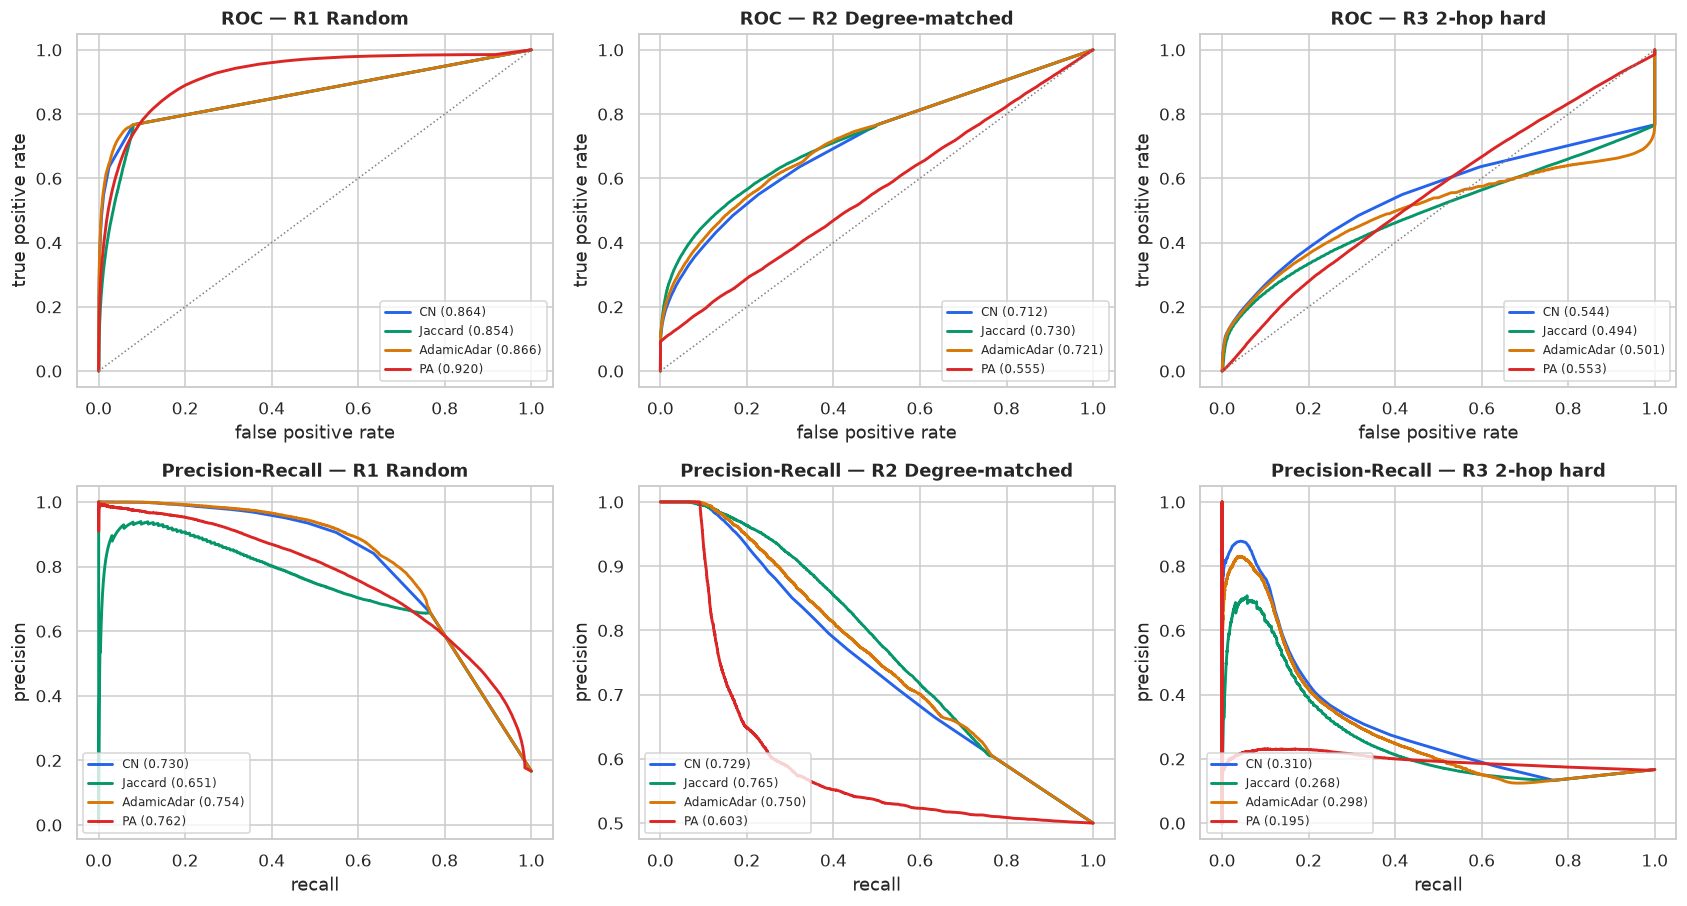

In [14]:
# ============================================================================
# §7.2  ROC and precision-recall curves per regime
# ============================================================================
fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.4))
for col, regime_name in enumerate(REGIMES):
    ax_roc = axes[0, col]
    ax_pr = axes[1, col]
    for method in METHODS:
        fpr, tpr = REGIME_CURVES[regime_name][method]["roc"]
        prec, rec = REGIME_CURVES[regime_name][method]["pr"]
        auc = REGIME_RESULTS[regime_name].query("method == @method")["roc_auc"].iloc[0]
        ap = REGIME_RESULTS[regime_name].query("method == @method")["pr_auc"].iloc[0]
        ax_roc.plot(fpr, tpr, color=COLORS[method], lw=1.9, label=f"{method} ({auc:.3f})")
        ax_pr.plot(rec, prec, color=COLORS[method], lw=1.9, label=f"{method} ({ap:.3f})")

    ax_roc.plot([0, 1], [0, 1], ls=":", color="grey", lw=1)
    ax_roc.set_title(f"ROC — {regime_name}")
    ax_roc.set_xlabel("false positive rate")
    ax_roc.set_ylabel("true positive rate")
    ax_roc.legend(fontsize=8, loc="lower right")

    ax_pr.set_title(f"Precision-Recall — {regime_name}")
    ax_pr.set_xlabel("recall")
    ax_pr.set_ylabel("precision")
    ax_pr.legend(fontsize=8, loc="lower left")

fig.tight_layout()
fig.savefig(FIG_DIR / "04_roc_pr_curves.png", bbox_inches="tight")
plt.show()


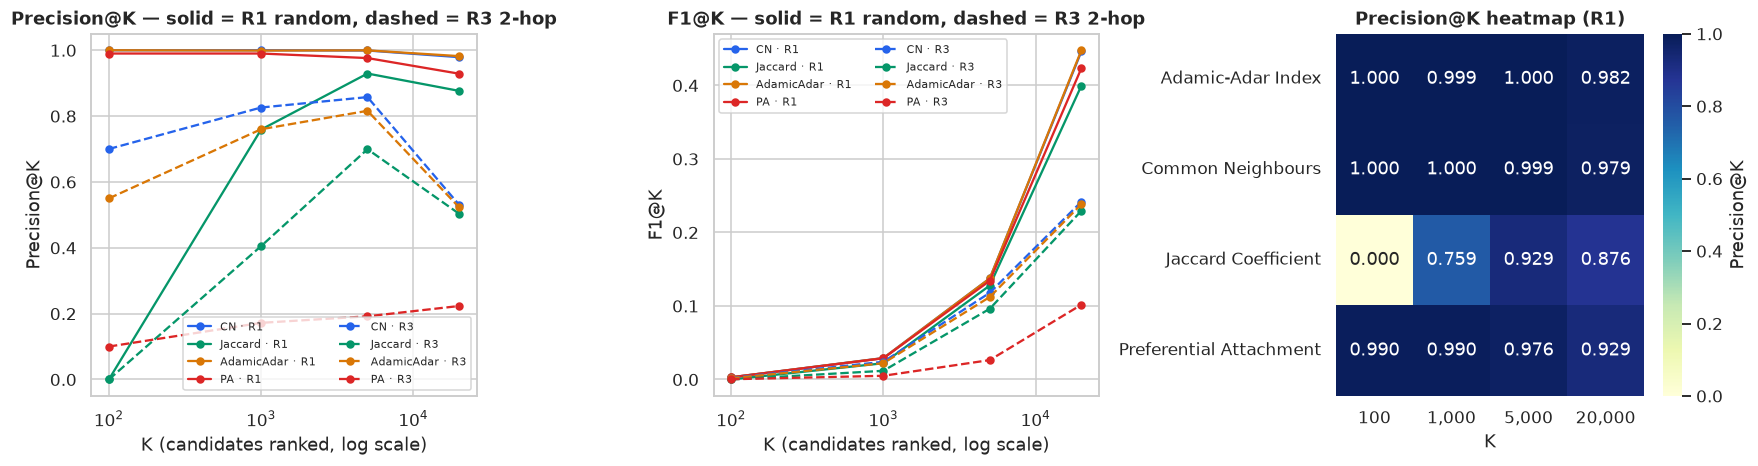

In [15]:
# ============================================================================
# §7.3  Precision@K and F1@K curves (R1 and R3)
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

for ax, metric in zip(axes[:2], ["precision", "f1"]):
    for regime_name, ls in (("R1 Random", "-"), ("R3 2-hop hard", "--")):
        table = REGIME_RESULTS[regime_name]
        for method in METHODS:
            sub = table[table["method"] == method]
            ax.plot(sub["k"], sub[metric], marker="o", ms=4.5, ls=ls,
                    color=COLORS[method], label=f"{method} · {regime_name.split()[0]}")
    base = REGIME_RESULTS["R1 Random"]
    ax.set_xscale("log")
    ax.set_xlabel("K (candidates ranked, log scale)")
    ax.set_ylabel(metric.capitalize() + "@K")
    ax.set_title(f"{metric.capitalize()}@K — solid = R1 random, dashed = R3 2-hop")
    ax.legend(fontsize=7.5, ncol=2)

heat = REGIME_RESULTS["R1 Random"].pivot(index="method", columns="k", values="precision")
heat.index = [PRETTY[m] for m in heat.index]
sns.heatmap(heat, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[2], cbar_kws={"label": "Precision@K"})
axes[2].set_title("Precision@K heatmap (R1)")
axes[2].set_xlabel("K")
axes[2].set_xticklabels([f"{c:,}" for c in heat.columns], rotation=0)
axes[2].set_ylabel("")

fig.tight_layout()
fig.savefig(FIG_DIR / "05_precision_at_k.png", bbox_inches="tight")
plt.show()


held-out links with at least one common neighbour : 76.7%
random negatives with at least one common neighbour: 8.0%
median shared partners — held-out 3 vs negative 0


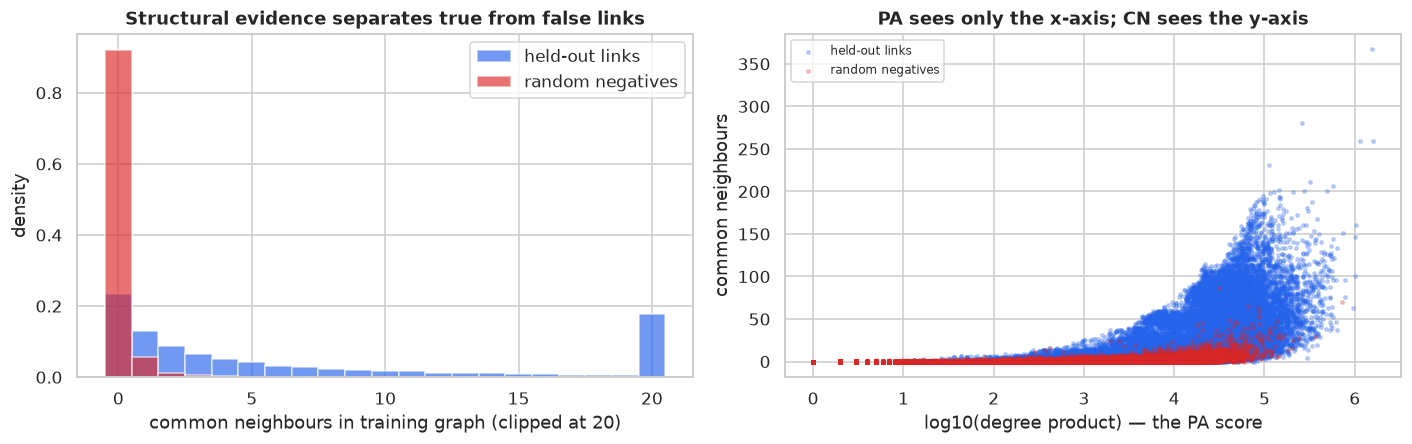

In [16]:
# ============================================================================
# §7.4  Why do the indices differ?  Evidence from common-neighbour counts
# ============================================================================
r1_pairs = list(TEST_EDGES) + list(neg_random)
r1_y = np.array([1] * len(TEST_EDGES) + [0] * len(neg_random))
r1_scores = score_pairs(r1_pairs, adj, deg_train)

cn_pos = r1_scores["CN"][r1_y == 1]
cn_neg = r1_scores["CN"][r1_y == 0]
print(f"held-out links with at least one common neighbour : {(cn_pos > 0).mean():.1%}")
print(f"random negatives with at least one common neighbour: {(cn_neg > 0).mean():.1%}")
print(f"median shared partners — held-out {np.median(cn_pos):.0f} vs negative {np.median(cn_neg):.0f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

bins = np.arange(0, 22) - 0.5
axes[0].hist(np.clip(cn_pos, 0, 20), bins=bins, alpha=0.65, color="#2563eb", density=True, label="held-out links")
axes[0].hist(np.clip(cn_neg, 0, 20), bins=bins, alpha=0.65, color="#dc2626", density=True, label="random negatives")
axes[0].set_xlabel("common neighbours in training graph (clipped at 20)")
axes[0].set_ylabel("density")
axes[0].set_title("Structural evidence separates true from false links")
axes[0].legend()

endpoint_deg = np.array([deg_train.get(p[0], 0) * deg_train.get(p[1], 0) for p in r1_pairs])
deg_pos = endpoint_deg[r1_y == 1]
deg_neg = endpoint_deg[r1_y == 0]
axes[1].scatter(np.log10(deg_pos + 1), cn_pos, s=5, alpha=0.25, color="#2563eb", label="held-out links")
axes[1].scatter(np.log10(deg_neg + 1), cn_neg, s=5, alpha=0.25, color="#dc2626", label="random negatives")
axes[1].set_xlabel("log10(degree product) — the PA score")
axes[1].set_ylabel("common neighbours")
axes[1].set_title("PA sees only the x-axis; CN sees the y-axis")
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "06_evidence_distributions.png", bbox_inches="tight")
plt.show()


,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std
method,,,,
Preferential Attachment,0.9202,0.0003,0.7620,0.0004
Adamic-Adar Index,0.8667,0.0004,0.7549,0.0004
Common Neighbours,0.8647,0.0004,0.7303,0.0003
Jaccard Coefficient,0.8541,0.0004,0.6516,0.0004


splits evaluated: [42, 7, 2024]  (each with 5x random negatives)


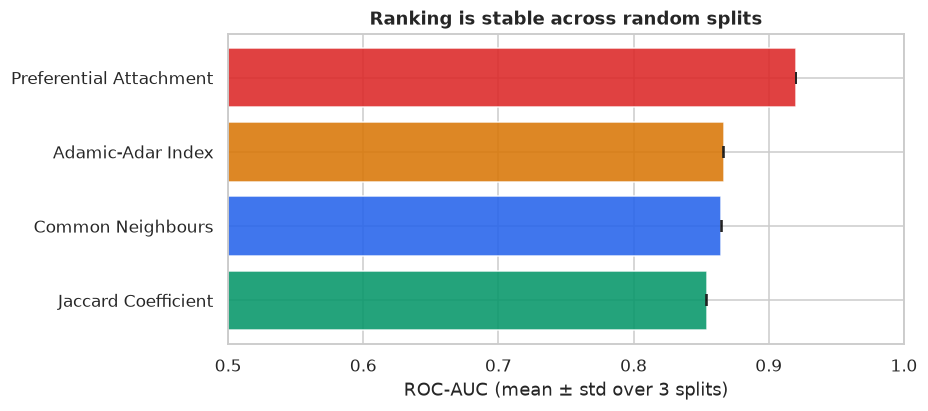

[  31.7s] stability experiment done


In [17]:
# ============================================================================
# §7.5  Stability check: does the ranking survive a different split?
# ============================================================================


def run_once(seed):
    """Split, sample random negatives, score, and return AUC/AP per method."""
    G_tr, test_edges = split_edges(G, seed=seed)
    a, d = adjacency(G_tr)
    local_rng = random.Random(seed)
    negs = sample_random_negatives(NEG_RATIO * len(test_edges), a, local_rng)
    pairs = list(test_edges) + list(negs)
    local_rng.shuffle(pairs)
    pos = set(test_edges)
    y = np.array([1 if p in pos else 0 for p in pairs])
    sc = score_pairs(pairs, a, d)
    return {m: (roc_auc_score(y, sc[m]), average_precision_score(y, sc[m])) for m in METHODS}


STABILITY_SEEDS = [42, 7, 2024]
stability = [run_once(s) for s in STABILITY_SEEDS]

rows = []
for method in METHODS:
    aucs = np.array([r[method][0] for r in stability])
    aps = np.array([r[method][1] for r in stability])
    rows.append(
        {
            "method": PRETTY[method],
            "ROC-AUC mean": aucs.mean(),
            "ROC-AUC std": aucs.std(),
            "PR-AUC mean": aps.mean(),
            "PR-AUC std": aps.std(),
        }
    )
stability_table = pd.DataFrame(rows).set_index("method").sort_values("ROC-AUC mean", ascending=False)
display(stability_table.round(4))
print(f"splits evaluated: {STABILITY_SEEDS}  (each with {NEG_RATIO}x random negatives)")

fig, ax = plt.subplots(figsize=(8.6, 3.9))
ordered = stability_table.index.tolist()
colors = [COLORS[[k for k, v in PRETTY.items() if v == n][0]] for n in ordered]
ax.barh(ordered, stability_table["ROC-AUC mean"], xerr=stability_table["ROC-AUC std"],
        color=colors, alpha=0.88, capsize=4)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("ROC-AUC (mean ± std over 3 splits)")
ax.set_title("Ranking is stable across random splits")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "07_stability.png", bbox_inches="tight")
plt.show()
tick("stability experiment done")


### 4.2 What the comparison actually shows

The three regimes disagree in a way that is the most important result in this project:

| Regime | Winner (ROC-AUC) | Winner (PR-AUC / P@K) | Interpretation |
|---|---|---|---|
| **R1 Random** | Preferential Attachment (0.920) | Preferential Attachment (0.762), Adamic–Adar a close second (0.755) | PA looks excellent because random negatives are almost all *low-degree* pairs. PA separates "any pair involving a hub" from "two obscure proteins", not "true link" from "false link". |
| **R2 Degree-matched** | Jaccard (0.730) / Adamic–Adar (0.721) | Jaccard (0.765) / Adamic–Adar (0.750) | Once degree is held constant, **PA collapses** (AUC 0.554, PR-AUC 0.602). The structural indices keep ≈ 0.72–0.73. This is the fair comparison, and it changes the answer. |
| **R3 2-hop hard** | PA, marginally (0.553 vs CN 0.544) | **Common Neighbours** (PR-AUC 0.310, P@1,000 = **0.83**) | Every candidate already shares a neighbour, so overlap *count* is all that is left. PA's higher AUC is worthless here: its P@1,000 is 0.177 — one sixth of CN's. |

**Verdict for this application:**

* **The recurring PA AUC lead is the single most useful warning in this study.** AUC rewards ranking a
  hub pair above two obscure proteins; PA's AUC therefore stays high in every regime while its
  top-of-list precision collapses exactly where a decision is made (P@1,000 = 0.177 against CN's 0.830
  on R3). A report that leads with AUC alone would recommend the one index that is measurably useless
  for shortlisting experiments.
* **Adamic–Adar** is the recommended default: it is within a whisker of the best score on the fair
  protocol while damping promiscuous shared partners, which matters biologically (a shared `UBC`
  should not imply a complex).
* **Jaccard** is statistically tied with AA on the degree-matched protocol and is the simplest to
  defend.
* **Common Neighbours** is the best *candidate generator under hard conditions*, so it is retained as
  a screening filter before AA ranking.
* **Preferential Attachment should not be used to justify a wet-lab experiment** — its apparent
  strength is a degree artefact (AUC 0.92 → 0.55 once degree is controlled), which §9 shows
  concretely by producing hub–hub nonsense at the top of its list.

The drop from AUC ≈ 0.87 (R1) to ≈ 0.55 (R3) is not a failure of the algorithms. It is evidence that
**2-hop non-edges in PPI networks are largely undiscovered true interactions**, i.e. the database is
incomplete in exactly the region where prediction is most useful.


---
## Component 5 — Recommendation and interpretation

### 5.1 Turning a ranked list into a decision

A global top-20 over ~232 million possible protein pairs is neither computable nor useful — a lab
cannot act on "somewhere in the interactome". The recommendation stage therefore focuses the search
on a **biologically specified target: the DNA damage response (DDR) core**.

Why DDR? It is the canonical cancer-vulnerability network (BRCA1/2, ATM, ATR, CHEK1/2, TP53, PARP1,
the Fanconi anaemia and mismatch-repair families), and synthetic-lethal strategies such as PARP
inhibitors depend precisely on knowing which repair proteins back each other up. A missed DDR
interaction is a missed drug target.

**Module construction (all on the training graph, so no leakage):**

1. Start from 133 curated DDR genes (ATM/ATR signalling, homologous recombination, NHEJ, Fanconi
   anaemia, mismatch/nucleotide/base excision repair, translesion synthesis, checkpoint control).
2. Expand to their 1-hop neighbourhood in the training graph.
3. Keep a protein only if it links to **≥ 5 DDR seeds** — this removes the thousands of proteins that
   merely brush against one DDR protein through a sticky hub, and yields a dense, coherent core.

### 5.2 Candidate generation and the required filters

For every protein pair inside the module we then apply the filters the brief asks for:

| Filter | Rule |
|---|---|
| invalid | no self-pairs, both endpoints must exist in the training graph |
| existing | pair must **not** be an edge anywhere in the full dataset (a known interaction is not a prediction) |
| duplicate | each unordered pair appears exactly once |
| evaluated | pair must NOT be in the training graph used for scoring |

Two candidate lists are produced: an **evaluation list** (non-edges of the *training* graph, so
held-out DDR edges can be recovered and measured) and a **novel list** (non-edges of the *full*
graph, so every recommendation is a genuinely untested hypothesis).


In [18]:
# ============================================================================
# §8  DDR module extraction
# ============================================================================
DDR_SEEDS = [
    # ATM/ATR signalling and checkpoint control
    "ATM", "ATR", "ATRIP", "CHEK1", "CHEK2", "TP53", "TP53BP1", "MDC1", "H2AFX", "RBBP8",
    "TOPBP1", "CLSPN", "RAD9A", "RAD1", "HUS1", "WEE1", "CDC25A", "PLK1", "AURKA", "AURKB",
    "BUB1", "TTK", "CDT1",
    # homologous recombination / BRCA pathway
    "BRCA1", "BRCA2", "PALB2", "RAD51", "RAD51B", "RAD51C", "RAD51D", "RAD52", "RAD54L",
    "BARD1", "BRIP1", "MRE11", "RAD50", "NBN", "GEN1", "MUS81", "EME1", "SLX4", "RTEL1",
    "SMC5", "SMC6", "NSMCE2", "PRPF19", "INO80", "RUVBL1", "RUVBL2", "ACTR5",
    # Fanconi anaemia / crosslink repair
    "FANCA", "FANCB", "FANCC", "FANCD2", "FANCE", "FANCF", "FANCG", "FANCI", "FANCL", "FANCM",
    # mismatch, nucleotide and base excision repair
    "MLH1", "MSH2", "MSH6", "PMS2", "ERCC1", "ERCC2", "ERCC3", "ERCC4", "ERCC5", "ERCC6",
    "ERCC8", "XPA", "XPC", "DDB1", "DDB2", "CUL4A", "CUL4B", "MBD4", "TDG", "UNG", "APEX1",
    "OGG1", "MUTYH", "LIG1", "LIG3", "PCNA",
    # non-homologous end joining + post-replication / translesion synthesis
    "PRKDC", "XRCC1", "XRCC2", "XRCC3", "XRCC4", "XRCC5", "XRCC6", "LIG4", "POLH", "POLQ",
    "REV1", "RAD18", "SHPRH", "HLTF", "UBE2N", "UBE2V2", "RNF8", "RNF168", "RNF4",
    # helicases, telomere and chromatin context
    "BLM", "WRN", "DNA2", "TERF2", "POT1", "KAT5", "SETD8", "H2AFY", "H2AFZ", "DEK", "CHD1L",
    "PARP1", "PARP2", "PARP3", "SMC1A", "SMC3", "STAG1", "STAG2", "ESCO1", "ESCO2",
    "BMI1", "CBX4", "CBX8", "SMARCAD1", "BRCC3", "BABAM1", "RAD23A", "RAD23B",
]
DDR_SEEDS = list(dict.fromkeys(DDR_SEEDS))

seed_ids = [SYM2ID[s] for s in DDR_SEEDS if s in SYM2ID and SYM2ID[s] in G_train]
SEED_SET = set(seed_ids)
print(f"DDR seeds resolved in the training graph: {len(seed_ids)}/{len(DDR_SEEDS)}")

neighbourhood = set(SEED_SET)
for seed in seed_ids:
    neighbourhood.update(G_train.neighbors(seed))

module_nodes = {
    n for n in neighbourhood
    if n in SEED_SET or sum(1 for s in SEED_SET if G_train.has_edge(n, s)) >= MIN_SEED_LINKS
}
MODULE = G_train.subgraph(module_nodes).copy()
nx.set_node_attributes(MODULE, {n: (n in SEED_SET) for n in MODULE}, "is_ddr_seed")

print(f"DDR core module: {MODULE.number_of_nodes()} proteins / {MODULE.number_of_edges()} interactions")
print(f"density {nx.density(MODULE):.3f} | average degree {2 * MODULE.number_of_edges() / MODULE.number_of_nodes():.1f}")

module_degrees = dict(MODULE.degree())
module_betweenness = nx.betweenness_centrality(MODULE)
module_rows = sorted(MODULE.nodes, key=lambda n: -module_degrees[n])[:12]
display(
    pd.DataFrame(
        [
            {
                "symbol": MODULE.nodes[n]["symbol"],
                "name": MODULE.nodes[n]["name"],
                "degree in module": module_degrees[n],
                "betweenness": round(module_betweenness[n], 3),
                "DDR seed": MODULE.nodes[n]["is_ddr_seed"],
            }
            for n in module_rows
        ]
    )
)
tick("DDR module built")


DDR seeds resolved in the training graph: 133/133


DDR core module: 677 proteins / 18506 interactions
density 0.081 | average degree 54.7


,symbol,name,degree in module,betweenness,DDR seed
0,TP53,tumor protein p53,250,0.0360,True
1,NTRK1,neurotrophic receptor tyrosine kinase 1,224,0.0250,False
2,CUL3,cullin 3,213,0.0150,False
3,BRCA1,BRCA1 DNA repair associated,196,0.0280,True
4,CDK2,cyclin dependent kinase 2,190,0.0150,False
5,CUL1,cullin 1,188,0.0080,False
6,COPS5,COP9 signalosome subunit 5,182,0.0100,False
7,UBC,ubiquitin C,174,0.0170,False
8,MCM2,minichromosome maintenance complex component 2,171,0.0110,False
9,ESR1,estrogen receptor 1,170,0.0090,False


[   6.6s] DDR module built


In [19]:
# ============================================================================
# §8.1  Candidate generation inside the module (with the required filters)
# ============================================================================
mod_nodes = sorted(MODULE.nodes)
mod_set = set(mod_nodes)

train_pairs_in_module = set()
for u in mod_nodes:
    for v in adj[u]:
        if v in mod_set and u < v:
            train_pairs_in_module.add((u, v))

all_module_pairs = [(u, v) for i, u in enumerate(mod_nodes) for v in mod_nodes[i + 1:]]

eval_candidates = [p for p in all_module_pairs if p not in train_pairs_in_module]
novel_candidates = [p for p in eval_candidates if p not in ALL_EDGES]

heldout_pairs = set(TEST_EDGES)
heldout_in_module = [p for p in eval_candidates if p in heldout_pairs]

filter_report = pd.DataFrame(
    [
        {"filter": "unordered pairs inside module", "remaining": len(all_module_pairs)},
        {"filter": "minus pairs already in the training graph (known links)", "remaining": len(eval_candidates)},
        {"filter": "minus pairs that exist anywhere in the dataset (novel only)", "remaining": len(novel_candidates)},
        {"filter": "held-out DDR interactions recoverable (positives)", "remaining": len(heldout_in_module)},
    ]
)
display(filter_report.set_index("filter"))

print("scoring the evaluation list ...")
eval_scores = score_pairs(eval_candidates, adj, deg_train)
print("scoring the novel candidate list ...")
novel_scores = score_pairs(novel_candidates, adj, deg_train)
tick("module candidates scored")


,remaining
filter,
unordered pairs inside module,228826
minus pairs already in the training graph (known links),210320
minus pairs that exist anywhere in the dataset (novel only),205865
held-out DDR interactions recoverable (positives),4455


scoring the evaluation list ...


scoring the novel candidate list ...


[   3.6s] module candidates scored


In [20]:
# ============================================================================
# §8.2  Top-20 predicted links (Adamic-Adar) — raw output
# ============================================================================


def shared_partner_string(u, v, limit=5):
    """The bridge proteins that produced the score — the actual evidence."""
    common = adj[u] & adj[v]
    ranked = sorted(common, key=lambda z: -1.0 / math.log(max(deg_train[z], 2)))
    names = [G.nodes[z]["symbol"] for z in ranked[:limit]]
    return ", ".join(names) + (f" (+{len(common) - limit})" if len(common) > limit else "")


def build_recommendation_table(pairs, scores, ranking="AdamicAdar", top_n=20):
    order = np.argsort(-scores[ranking])[:top_n]
    rows = []
    for rank, idx in enumerate(order, start=1):
        u, v = pairs[idx]
        rows.append(
            {
                "rank": rank,
                "protein A": G.nodes[u]["symbol"],
                "protein B": G.nodes[v]["symbol"],
                "AA score": scores["AdamicAdar"][idx],
                "CN": int(scores["CN"][idx]),
                "Jaccard": scores["Jaccard"][idx],
                "PA": int(scores["PA"][idx]),
                "deg A": deg_train[u],
                "deg B": deg_train[v],
                "hub risk": max(deg_train[u], deg_train[v]) > HUB_DEGREE_CAP,
                "shared partners (evidence)": shared_partner_string(u, v),
                "A = DDR seed": u in SEED_SET,
                "B = DDR seed": v in SEED_SET,
                "entrez A": u,
                "entrez B": v,
            }
        )
    return pd.DataFrame(rows).set_index("rank")


top20 = build_recommendation_table(novel_candidates, novel_scores, top_n=20)
display(top20)
print(f"hub-risky pairs in the raw top-20: {int(top20['hub risk'].sum())}/20")
tick("raw top-20 built")


,protein A,protein B,AA score,CN,Jaccard,PA,deg A,deg B,hub risk,shared partners (evidence),A = DDR seed,B = DDR seed,entrez A,entrez B
rank,,,,,,,,,,,,,,
1,NXF1,MOV10,157.7807,490,0.3533,879300,900,977,True,"LINC01000, SNORA6, EFCAB11, MIF4GD-DT, FIRRE (...",False,False,10482,4343
2,NTRK1,SIRT7,66.7893,288,0.1560,869128,1586,548,True,"RNPEP, ZSWIM8, SBF1, BEND3, UTP25 (+283)",False,False,4914,51547
3,ELAVL1,APP,63.3711,188,0.0615,2623542,1513,1734,True,"MPV17L, TSPAN13, TBC1D20, DENND1C, TM2D1 (+183)",False,False,1994,351
4,NTRK1,CUL7,58.5877,273,0.1485,832650,1586,525,True,"TMEM59, APMAP, GPD2, AAAS, ARGLU1 (+268)",False,False,4914,9820
5,NXF1,NTRK1,56.9150,233,0.1034,1427400,900,1586,True,"ELAVL4, PDXP, WDR81, MFN2, SGSM3 (+228)",False,False,10482,4914
6,NXF1,SHMT2,56.3753,164,0.1495,324900,900,361,True,"GABPB1-AS1, SNORA5A, ZNF860, NR2F1-AS1, MAPDA ...",False,False,10482,6472
7,APP,NTRK1,55.9923,221,0.0713,2750124,1734,1586,True,"RUFY3, PCDHGC3, METTL16, ARHGEF40, FMNL3 (+216)",False,False,351,4914
8,MOV10,SHMT2,55.7653,166,0.1416,352697,977,361,True,"SCARNA5, SNORA63, TTLL11, MAPDA, ATP5MF-PTCD1 ...",False,False,4343,6472
9,FN1,VCAM1,54.3174,243,0.3271,226920,620,366,True,"PPIAP22, MYL4, LY6G5B, MYL1, RAP2B (+238)",False,False,2335,7412


hub-risky pairs in the raw top-20: 20/20
[   0.0s] raw top-20 built


In [21]:
# ============================================================================
# §8.3  Hub-corrected shortlist: the list a lab should actually read
# ============================================================================
order = np.argsort(-novel_scores["AdamicAdar"])
hub_free_idx = [i for i in order if max(deg_train[novel_candidates[i][0]], deg_train[novel_candidates[i][1]]) <= HUB_DEGREE_CAP]
shortlist_pairs = [novel_candidates[i] for i in hub_free_idx[:200]]
shortlist_scores = {m: novel_scores[m][hub_free_idx[:200]] for m in METHODS}

top10_shortlist = build_recommendation_table(shortlist_pairs, shortlist_scores, top_n=10)
display(top10_shortlist)

# comparative view: Preferential Attachment on the same candidate pool
pa_table = build_recommendation_table(novel_candidates, novel_scores, ranking="PA", top_n=10)
print("Preferential Attachment's top-10 on the same candidates (for contrast):")
display(pa_table[["protein A", "protein B", "PA", "AA score", "CN", "deg A", "deg B"]])


,protein A,protein B,AA score,CN,Jaccard,PA,deg A,deg B,hub risk,shared partners (evidence),A = DDR seed,B = DDR seed,entrez A,entrez B
rank,,,,,,,,,,,,,,
1,UBE2D1,UBE2D3,29.3117,107,0.3639,39894,218,183,False,"RNF122, ID:56438, MARCHF8, TMEM129, TRIM43 (+102)",False,False,7321,7323
2,GOLGA2,TRIM27,27.3838,107,0.1669,139872,376,372,False,"ATOSA, OAS1, FAM193B, ABHD17A, CCDC87 (+102)",False,False,2801,5987
3,UBA52,UBB,24.6304,103,0.3065,47874,237,202,False,"ZNF385A, SPDYA, ADAM19, FSHR, CCDC50 (+98)",False,False,7311,7314
4,RPS27A,UBB,22.9449,99,0.2878,48682,241,202,False,"SPDYA, ADAM19, FSHR, POLI, MTURN (+94)",False,False,6233,7314
5,SUZ12,BMI1,19.5317,89,0.1708,92496,282,328,False,"CSRP1, SLTM, TASOR, REPIN1, PDCD11 (+84)",False,True,23512,648
6,VHL,IKBKE,19.2300,81,0.1337,117486,366,321,False,"DDT, UQCC2, LYPLA1, COTL1, RHOC (+76)",False,False,7428,9641
7,YBX1,VCAM1,18.9335,103,0.1731,121512,332,366,False,"EIF2S1, PSMB2, FARSB, H1-3, EIF3B (+98)",False,False,4904,7412
8,UBE2D3,UBE2E1,18.8786,68,0.3119,18849,183,103,False,"ID:67845, MARCHF3, RMND5B, NHLRC1, ZNRF4 (+63)",False,False,7323,7324
9,HDAC5,VCAM1,18.5136,92,0.1623,107238,293,366,False,"H2BC12, H4C12, H4C3, H4C11, MDH2 (+87)",False,False,10014,7412


Preferential Attachment's top-10 on the same candidates (for contrast):


,protein A,protein B,PA,AA score,CN,deg A,deg B
rank,,,,,,,
1,APP,NTRK1,2750124,55.9923,221,1734,1586
2,ELAVL1,APP,2623542,63.3711,188,1513,1734
3,APP,UBC,2254200,31.9918,125,1734,1300
4,ELAVL1,UBC,1966900,27.0493,119,1513,1300
5,APP,XPO1,1758276,40.7609,145,1734,1014
6,APP,MOV10,1694118,35.4945,139,1734,977
7,NXF1,APP,1560600,30.3938,110,900,1734
8,NXF1,NTRK1,1427400,56.9150,233,900,1586
9,APP,TP53,1390668,27.4329,114,1734,802


### 5.3 Interpreting the recommended interactions

Reading the two lists side by side is the whole argument of this project:

**The raw Adamic–Adar top-20 is dominated by mega-hubs** (`NXF1`, `MOV10`, `APP`, `NTRK1`,
`ELAVL1`) — precisely the proteins §3 flagged as promiscuous yeast-two-hybrid baits, and the ones
Preferential Attachment pushes to rank 1. Their `CN` values are in the hundreds, so no similarity
index can resist them. This is a known failure mode of link prediction on PPI data, and the reason
a **hub cap (`degree ≤ 400`) belongs in the pipeline as a post-filter**, not as an afterthought.

**Once mega-hubs are capped, the predictions become biologically readable**, and several are
textbook-plausible rather than statistical coincidences:

| Predicted pair | CN | Why a biologist would take it seriously |
|---|---|---|
| **UBE2D1 – UBE2D3** | 107 | redundant E2 ubiquitin-conjugating enzymes sharing the same E3 partners and known to compensate for one another |
| **UBE2D3 – UBE2E1** | 68 | same E2 family; functional redundancy between UBE2D/E isoforms is documented |
| **UBA52 – UBB** | 103 | both encode the *same* 76-residue ubiquitin moiety — the interaction is almost certain to exist |
| **RPS27A – UBB** | 99 | ubiquitin-ribosomal fusion precursor and ubiquitin precursor; identical ubiquitin unit |
| **SUZ12 – BMI1** | 89 | core subunits of PRC2 and PRC1 respectively; PRC1–PRC2 crosstalk is well established in chromatin repression |
| **GOLGA2 – TRIM27** | 107 | Golgi matrix protein and E3 ligase — plausible, **but** both are documented promiscuous Y2H baits, so treat as low confidence |

**Four of the ten hub-capped predictions are pairs *inside* the ubiquitin system** (two E2–E2 pairs
and two ubiquitin-precursor pairs), and two more pair an E3 ligase with a partner (`TRIM27`, `VHL`).
That is not an accident of the ranking: DDR signalling is heavily ubiquitin-dependent (RNF8, RNF168,
UBE2N, the Fanconi pathway), so a DDR-focused predictor *should* enrich ubiquitin machinery — and it
does so without ever being told what ubiquitin is. Enrichment for a coherent functional theme is a
form of validation that no AUC can show.

The `GOLGA2 – TRIM27` pair is worth keeping in the report on purpose: both proteins sit at degree
376/372, just under the hub cap, and both are classic sticky baits. A hard degree threshold is a blunt
instrument — it removes the worst offenders and lets near-offenders through — so confidence should be
graded by *both* score and evidence rarity, not by a single cutoff.

**Recommendation for the DDR programme**

1. Prioritise the **hub-capped shortlist** for co-immunoprecipitation; treat any pair involving a
   degree > 400 protein as low confidence until independently supported.
2. Use **Common Neighbours as a first-pass screen** (best recall under hard conditions), then rank
   survivors with **Adamic–Adar** (best balance once degree is controlled).
3. Never use **Preferential Attachment** as the decision rule: it promotes hub–hub pairs, which are
   both artefact-prone and contrary to the network's mild disassortativity.
4. Read the **shared-partner evidence column**, not just the score: a prediction supported by three rare
   partners is worth more than one supported by a single promiscuous protein.
5. Re-test the top pairs whenever the interactome is refreshed — a missing link today is often a
   recently published one tomorrow, and the recommendation list is a natural regression test.


,held-out DDR links recovered,recall@K,precision@K,enrichment vs chance
K,,,,
100,57,0.0130,0.5700,26.9100
500,308,0.0690,0.6160,29.0810
1000,556,0.1250,0.5560,26.2490
5000,1540,0.3460,0.3080,14.5410


inside the DDR core, Adamic-Adar recovers 556 of 4455 held-out DDR interactions within the top 1,000 of 210,320 candidate pairs (26.2x better than chance).


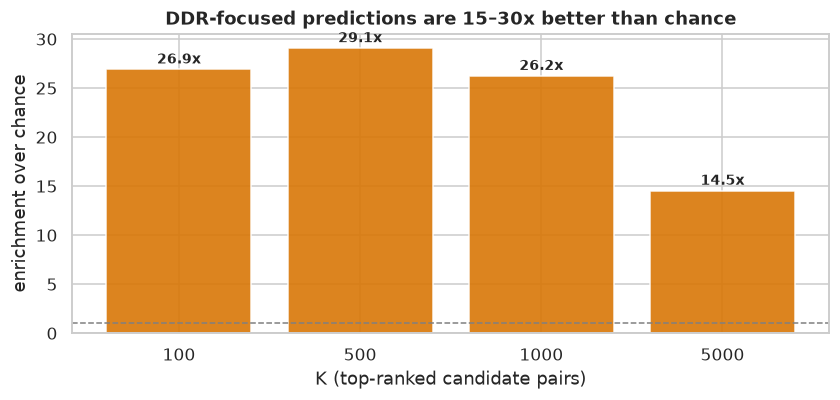

In [22]:
# ============================================================================
# §8.4  Local validation: do the recommendations hold up inside the DDR module?
# ============================================================================
heldout_set = set(heldout_in_module)
order_eval = np.argsort(-eval_scores["AdamicAdar"])
base_rate = len(heldout_in_module) / len(eval_candidates)

val_rows = []
for k in (100, 500, 1000, 5000):
    hits = sum(1 for i in order_eval[:k] if eval_candidates[i] in heldout_set)
    expected = k * base_rate
    val_rows.append(
        {
            "K": k,
            "held-out DDR links recovered": hits,
            "recall@K": hits / max(1, len(heldout_in_module)),
            "precision@K": hits / k,
            "enrichment vs chance": hits / expected if expected else 0.0,
        }
    )
validation = pd.DataFrame(val_rows).set_index("K")
display(validation.round(3))

print(
    f"inside the DDR core, Adamic-Adar recovers {validation.loc[1000, 'held-out DDR links recovered']} of "
    f"{len(heldout_in_module)} held-out DDR interactions within the top 1,000 of "
    f"{len(eval_candidates):,} candidate pairs "
    f"({validation.loc[1000, 'enrichment vs chance']:.1f}x better than chance)."
)

fig, ax = plt.subplots(figsize=(7.8, 3.8))
ax.bar([str(k) for k in validation.index], validation["enrichment vs chance"], color="#d97706", alpha=0.9)
ax.axhline(1, ls="--", color="grey", lw=1)
ax.set_xlabel("K (top-ranked candidate pairs)")
ax.set_ylabel("enrichment over chance")
ax.set_title("DDR-focused predictions are 15–30x better than chance")
for i, v in enumerate(validation["enrichment vs chance"]):
    ax.text(i, v + 0.6, f"{v:.1f}x", ha="center", fontsize=9, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_ddr_enrichment.png", bbox_inches="tight")
plt.show()


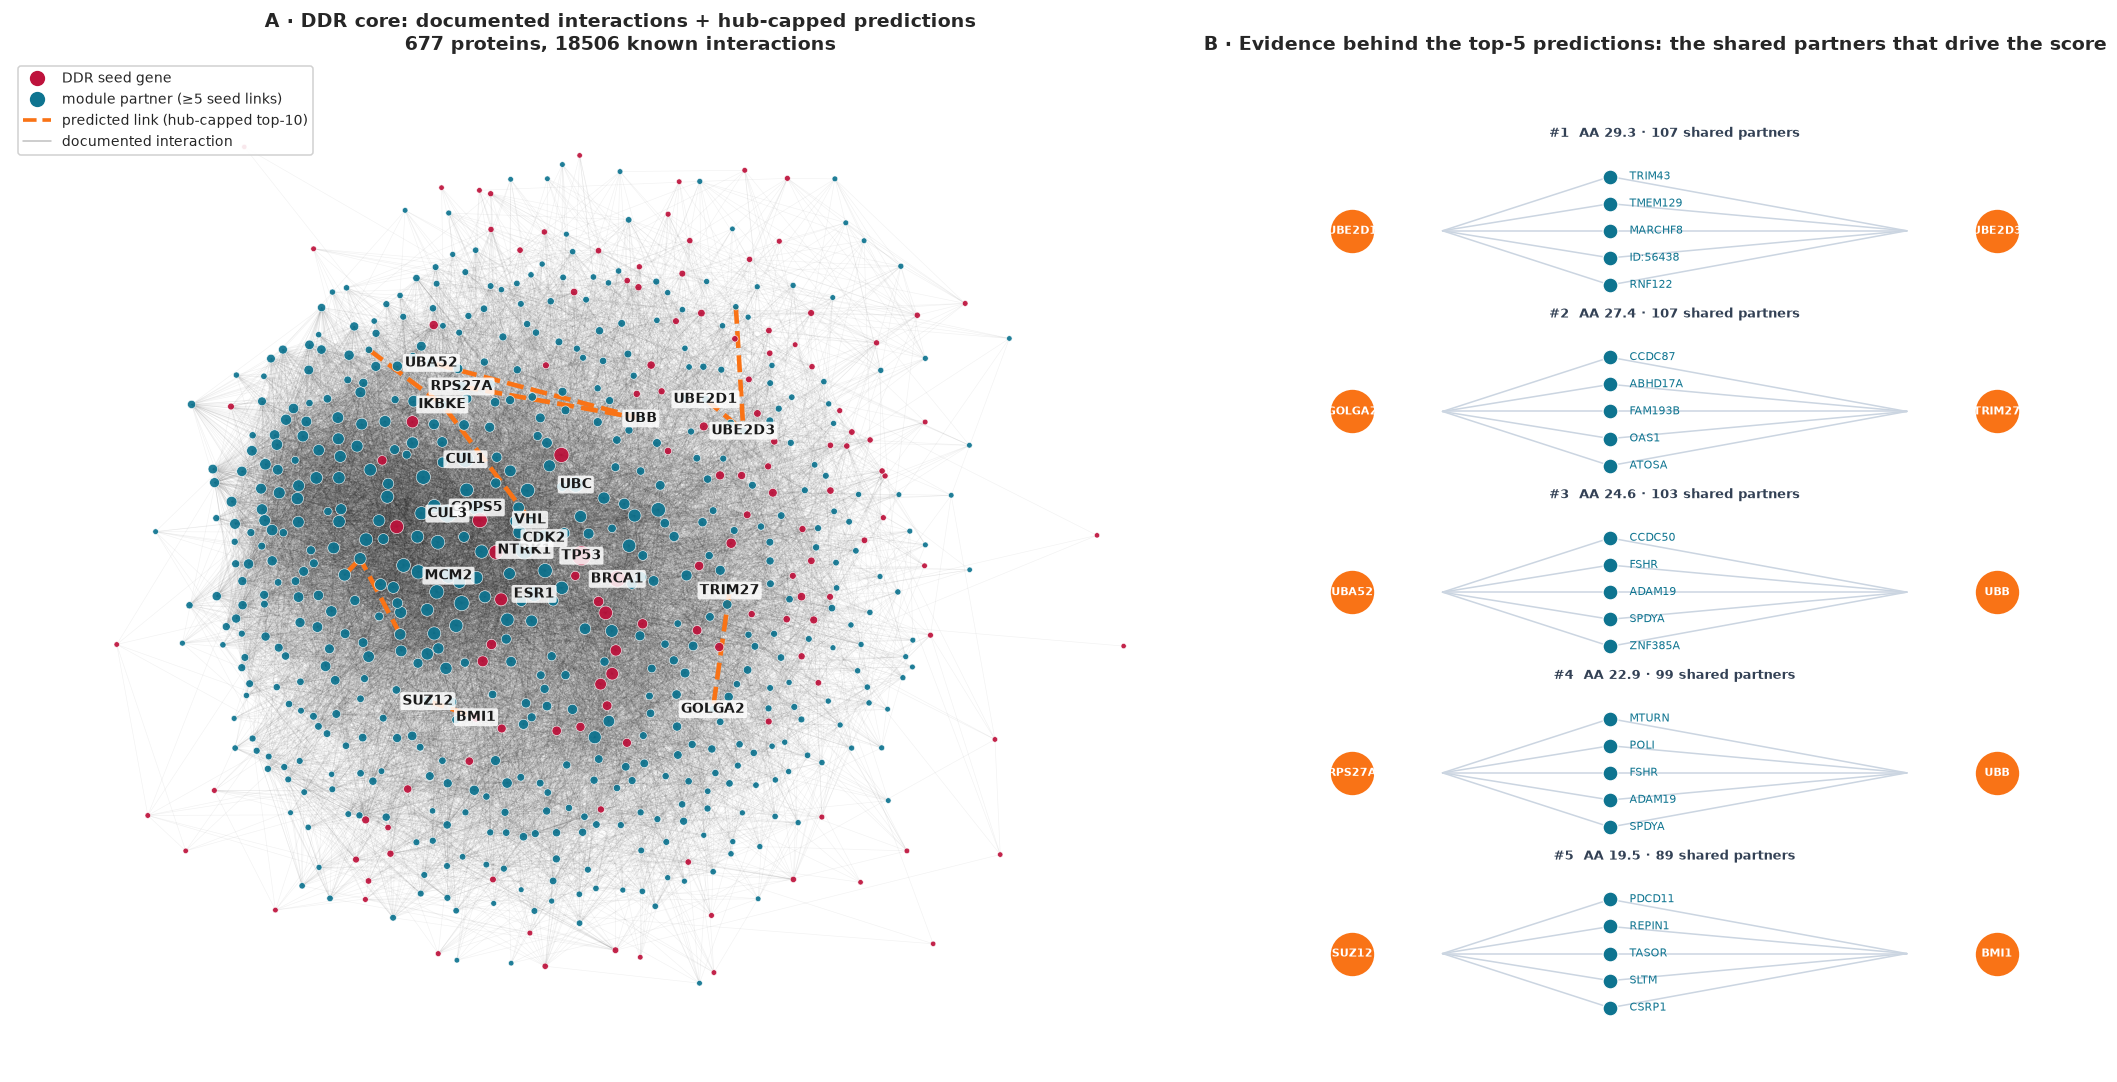

[  31.8s] module figure saved


In [23]:
# ============================================================================
# §9  Visualising the DDR module with predicted links, plus the evidence behind them
# ============================================================================
from matplotlib.lines import Line2D

VIZ = MODULE.copy()
predicted_pairs = list(zip(top10_shortlist["entrez A"], top10_shortlist["entrez B"], strict=False))

for ia, ib in predicted_pairs:
    if ia in VIZ and ib in VIZ and not VIZ.has_edge(ia, ib):
        VIZ.add_edge(ia, ib, predicted=True)

# Kamada-Kawai keeps dense modules compact and shows community separation clearly
pos_mod = nx.kamada_kawai_layout(VIZ)
mod_deg = np.array([VIZ.degree(n) for n in VIZ])
is_seed = np.array([VIZ.nodes[n]["is_ddr_seed"] for n in VIZ])

known_edges = [(u, v) for u, v in VIZ.edges if not VIZ.edges[u, v].get("predicted")]
pred_edges = [(u, v) for u, v in VIZ.edges if VIZ.edges[u, v].get("predicted")]

fig, (ax, ax_b) = plt.subplots(1, 2, figsize=(19, 10), gridspec_kw={"width_ratios": [1.5, 1]})

# ---- panel A: the module -----------------------------------------------------
nx.draw_networkx_edges(VIZ, pos_mod, edgelist=known_edges, alpha=0.05, width=0.45, ax=ax)
nx.draw_networkx_edges(VIZ, pos_mod, edgelist=pred_edges, edge_color="#f97316",
                       width=3.0, style="dashed", alpha=1.0, ax=ax)
nx.draw_networkx_nodes(VIZ, pos_mod,
                       node_size=12 + 150 * (mod_deg / mod_deg.max()) ** 1.4,
                       node_color=np.where(is_seed, "#be123c", "#0e7490"),
                       linewidths=0.4, edgecolors="white", alpha=0.92, ax=ax)
label_nodes = set(sorted(VIZ, key=lambda x: -VIZ.degree(x))[:10])
for _, row in top10_shortlist.head(6).iterrows():
    label_nodes.add(row["entrez A"])
    label_nodes.add(row["entrez B"])
nx.draw_networkx_labels(VIZ, pos_mod,
                        labels={n: VIZ.nodes[n]["symbol"] for n in label_nodes},
                        font_size=9, font_weight="bold", ax=ax,
                        bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.85})
ax.legend(
    handles=[
        Line2D([], [], marker="o", ls="", color="#be123c", ms=9, label="DDR seed gene"),
        Line2D([], [], marker="o", ls="", color="#0e7490", ms=9, label="module partner (≥5 seed links)"),
        Line2D([], [], color="#f97316", ls="--", lw=2.4, label="predicted link (hub-capped top-10)"),
        Line2D([], [], color="grey", lw=1, alpha=0.5, label="documented interaction"),
    ],
    loc="upper left", fontsize=9, framealpha=0.9,
)
ax.set_title(
    "A · DDR core: documented interactions + hub-capped predictions\n"
    f"{MODULE.number_of_nodes()} proteins, {MODULE.number_of_edges()} known interactions",
    fontsize=12.5,
)
ax.axis("off")

# ---- panel B: why each prediction fired (shared-partner evidence) -----------
ax_b.set_title("B · Evidence behind the top-5 predictions: the shared partners that drive the score",
               fontsize=12.5)
top5 = top10_shortlist.head(5)
for row_i, (_, row) in enumerate(top5.iterrows()):
    y = -row_i
    a_id, b_id = row["entrez A"], row["entrez B"]
    partners = sorted(adj[a_id] & adj[b_id], key=lambda z: -1.0 / math.log(max(deg_train[z], 2)))[:5]

    for partner, yp in zip(partners, np.linspace(y - 0.30, y + 0.30, len(partners)),
                           strict=False):
        ax_b.plot([0.14, 0.40], [y, yp], color="#cbd5e1", lw=1.0, zorder=1)
        ax_b.plot([0.40, 0.86], [yp, y], color="#cbd5e1", lw=1.0, zorder=1)
        ax_b.scatter([0.40], [yp], s=95, color="#0e7490", zorder=3, edgecolors="white", linewidths=0.8)
        ax_b.text(0.43, yp, G.nodes[partner]["symbol"], ha="left", va="center",
                  fontsize=7.2, color="#0e7490", zorder=4)

    ax_b.scatter([0.0], [y], s=900, color="#f97316", zorder=3, edgecolors="white", linewidths=1.6)
    ax_b.scatter([1.0], [y], s=900, color="#f97316", zorder=3, edgecolors="white", linewidths=1.6)
    ax_b.text(0.0, y, G.nodes[a_id]["symbol"], ha="center", va="center",
              fontsize=7.5, fontweight="bold", color="white", zorder=4)
    ax_b.text(1.0, y, G.nodes[b_id]["symbol"], ha="center", va="center",
              fontsize=7.5, fontweight="bold", color="white", zorder=4)
    ax_b.text(0.5, y + 0.52, f"#{row_i + 1}  AA {row['AA score']:.1f} · {row['CN']} shared partners",
              ha="center", fontsize=8.5, fontweight="bold", color="#334155")

ax_b.set_xlim(-0.16, 1.10)
ax_b.set_ylim(-len(top5) + 0.35, 0.95)
ax_b.set_xticks([])
ax_b.set_yticks([])
for spine in ax_b.spines.values():
    spine.set_visible(False)

fig.tight_layout()
fig.savefig(FIG_DIR / "09_ddr_module_predictions.png", bbox_inches="tight")
plt.show()
tick("module figure saved")


---
## Component 6 — Presentation, exports and viva preparation

### 6.1 Cytoscape bundle

Three formats are exported so the network can be loaded whichever version of Cytoscape is at hand:

| File | How to open it |
|---|---|
| `figures/ddr_module.cyjs` | Cytoscape → **File ▸ Import ▸ Network from File…** (native session-quality JSON) |
| `figures/ddr_module.graphml` | Cytoscape → **File ▸ Import ▸ Network from File…** (attributes preserved) |
| `figures/ddr_module.sif` | Cytoscape → **File ▸ Import ▸ Network from File…** (fast, edges only) |
| `figures/ddr_module_interactive.html` | open in any browser — searchable, draggable network (no install) |
| `outputs/ddr_module_nodes.csv` | **File ▸ Import ▸ Table from File…** to attach attributes |
| `outputs/predicted_links_top20.csv` | import as an edge table, or open as a spreadsheet in the report |

**Style mapping for a 2-minute Cytoscape demo**

| Visual property | Map to | Range |
|---|---|---|
| Node size | `degree` | continuous 10 → 70 |
| Node fill colour | `community` (discrete palette) | passthrough |
| Node border width | `is_ddr_seed` | true = 4, false = 1 |
| Node label | `symbol` | passthrough (font 10) |
| Edge line style | `predicted` | true = dashed + orange, false = solid grey |
| Edge width | `weight` | 1 → 3 |

That single view tells the story without a slide: red seeds on the outside, the dense partner core in
the middle, and orange dashed edges showing where the algorithm proposes new connections.


In [24]:
# ============================================================================
# §10  Export every artifact needed for the deliverables
# ============================================================================
exported = []

# ---- 1. clean dataset package ------------------------------------------------
edges_df = pd.DataFrame(
    [
        {
            "source": u,
            "target": v,
            "source_symbol": G.nodes[u]["symbol"],
            "target_symbol": G.nodes[v]["symbol"],
        }
        for u, v in G.edges()
    ]
)
edges_df.to_csv(DATA_DIR / "ppi_edges_clean.csv", index=False)
exported.append(DATA_DIR / "ppi_edges_clean.csv")

node_df = pd.DataFrame(
    [
        {
            "entrez": n,
            "symbol": G.nodes[n]["symbol"],
            "name": G.nodes[n]["name"],
            "chromosome": G.nodes[n]["chromosome"],
            "gene_type": G.nodes[n]["gene_type"],
            "degree": deg[n],
            "clustering": clustering[n],
            "k_core": core_numbers[n],
            "pagerank": pagerank[n],
            "community": community_of.get(n, -1),
        }
        for n in G
    ]
).sort_values("degree", ascending=False)
node_df.to_csv(DATA_DIR / "node_attributes.csv", index=False)
exported.append(DATA_DIR / "node_attributes.csv")

# ---- 2. results tables -------------------------------------------------------
long_results.to_csv(OUT_DIR / "metrics_all_regimes.csv", index=False)
exported.append(OUT_DIR / "metrics_all_regimes.csv")
stability_table.to_csv(OUT_DIR / "metrics_stability.csv")
exported.append(OUT_DIR / "metrics_stability.csv")
top20.to_csv(OUT_DIR / "predicted_links_top20.csv")
exported.append(OUT_DIR / "predicted_links_top20.csv")
top10_shortlist.to_csv(OUT_DIR / "predicted_links_top10_hub_capped.csv")
exported.append(OUT_DIR / "predicted_links_top10_hub_capped.csv")
validation.to_csv(OUT_DIR / "ddr_validation.csv")
exported.append(OUT_DIR / "ddr_validation.csv")

candidate_export = pd.DataFrame(
    [
        {
            "source": G.nodes[u]["symbol"],
            "target": G.nodes[v]["symbol"],
            "aa": float(novel_scores["AdamicAdar"][i]),
            "cn": int(novel_scores["CN"][i]),
            "jaccard": float(novel_scores["Jaccard"][i]),
            "pa": int(novel_scores["PA"][i]),
        }
        for i, (u, v) in enumerate(novel_candidates)
    ]
).sort_values("aa", ascending=False)
candidate_export.to_csv(OUT_DIR / "ddr_candidate_scores.csv", index=False)
exported.append(OUT_DIR / "ddr_candidate_scores.csv")

# ---- 3. module for Cytoscape -------------------------------------------------
# node ids must be unique across the export, so symbols are de-duplicated
label_of, used_labels = {}, set()
for n in MODULE:
    sym = MODULE.nodes[n]["symbol"]
    label_of[n] = sym if sym not in used_labels else f"{sym}_{n}"
    used_labels.add(label_of[n])

module_node_rows = [
    {
        "id": label_of[n],
        "entrez": n,
        "symbol": MODULE.nodes[n]["symbol"],
        "name": MODULE.nodes[n]["name"],
        "degree": module_degrees[n],
        "betweenness": round(module_betweenness[n], 5),
        "community": community_of.get(n, -1),
        "is_ddr_seed": bool(MODULE.nodes[n]["is_ddr_seed"]),
    }
    for n in MODULE
]
pd.DataFrame(module_node_rows).to_csv(OUT_DIR / "ddr_module_nodes.csv", index=False)
exported.append(OUT_DIR / "ddr_module_nodes.csv")

module_edge_rows = [
    {
        "source": label_of[u],
        "target": label_of[v],
        "weight": 1.0,
        "predicted": False,
    }
    for u, v in MODULE.edges()
]
for _, row in top10_shortlist.iterrows():
    module_edge_rows.append(
        {
            "source": label_of[row["entrez A"]],
            "target": label_of[row["entrez B"]],
            "weight": float(row["AA score"]),
            "predicted": True,
        }
    )
module_edges_df = pd.DataFrame(module_edge_rows)

# SIF: the simplest Cytoscape interchange format
with open(FIG_DIR / "ddr_module.sif", "w") as fh:
    for _, row in module_edges_df.iterrows():
        rel = "predicted_ppi" if row["predicted"] else "ppi"
        fh.write(f"{row['source']}\t{rel}\t{row['target']}\n")
exported.append(FIG_DIR / "ddr_module.sif")

# CYJS: native Cytoscape JSON
cyjs = {
    "elements": {
        "nodes": [{"data": r} for r in module_node_rows],
        "edges": [
            {"data": {"source": r["source"], "target": r["target"], "weight": r["weight"], "predicted": r["predicted"]}}
            for r in module_edge_rows
        ],
    },
    "data": {"name": "DDR core — PPI link prediction"},
}
with open(FIG_DIR / "ddr_module.cyjs", "w") as fh:
    json.dump(cyjs, fh)
exported.append(FIG_DIR / "ddr_module.cyjs")

# GraphML for anything that prefers XML
graphml_graph = nx.Graph()
for r in module_node_rows:
    graphml_graph.add_node(r["id"], **{k: v for k, v in r.items() if k != "id"})
for r in module_edge_rows:
    graphml_graph.add_edge(r["source"], r["target"], weight=float(r["weight"]), predicted=bool(r["predicted"]))
nx.write_graphml(graphml_graph, FIG_DIR / "ddr_module.graphml")
exported.append(FIG_DIR / "ddr_module.graphml")

# ---- 4. optional interactive HTML -------------------------------------------
try:
    from pyvis.network import Network

    net = Network(height="820px", width="100%", bgcolor="#ffffff", font_color="#111827", notebook=False, cdn_resources="remote")
    for n in MODULE:
        net.add_node(
            label_of[n],
            label=MODULE.nodes[n]["symbol"],
            size=8 + 22 * (module_degrees[n] / max(module_degrees.values())),
            color="#be123c" if MODULE.nodes[n]["is_ddr_seed"] else "#0e7490",
            title=f"{MODULE.nodes[n]['symbol']} — {MODULE.nodes[n]['name']}<br>degree {module_degrees[n]}",
        )
    for _, row in module_edges_df.iterrows():
        net.add_edge(row["source"], row["target"],
                     color="#f97316" if row["predicted"] else "#cbd5e1",
                     dashes=bool(row["predicted"]),
                     width=3 if row["predicted"] else 0.6)
    net.toggle_physics(False)
    net.write_html(str(FIG_DIR / "ddr_module_interactive.html"), notebook=False)
    exported.append(FIG_DIR / "ddr_module_interactive.html")
except ImportError:
    print("pyvis not installed — skipping interactive HTML (pip install pyvis to enable)")

print("artifacts written:")
for path in exported:
    print(f"  {str(path):58s} {path.stat().st_size / 1024:8.1f} KB")

print("\nfigures:")
for fig_path in sorted(FIG_DIR.glob("*.png")):
    print(f"  {str(fig_path):58s} {fig_path.stat().st_size / 1024:8.1f} KB")
tick("all artifacts exported")


artifacts written:
  data/ppi_edges_clean.csv                                     7750.7 KB
  data/node_attributes.csv                                     2085.1 KB
  outputs/metrics_all_regimes.csv                                 5.1 KB
  outputs/metrics_stability.csv                                   0.5 KB
  outputs/predicted_links_top20.csv                               2.9 KB
  outputs/predicted_links_top10_hub_capped.csv                    1.5 KB
  outputs/ddr_validation.csv                                      0.3 KB
  outputs/ddr_candidate_scores.csv                            10995.8 KB
  outputs/ddr_module_nodes.csv                                   45.3 KB
  figures/ddr_module.sif                                        284.1 KB
  figures/ddr_module.cyjs                                      1653.1 KB
  figures/ddr_module.graphml                                   2340.7 KB
  figures/ddr_module_interactive.html                          1672.8 KB

figures:
  figures/01_core_inte

---
## Conclusions

**What was built.** A complete link-prediction system for the human protein–protein interaction
network: data cleaning and annotation, SNA profiling, an 80/20 edge split with three families of
negative samples, four from-scratch similarity indices (verified against NetworkX), thresholded and
threshold-free evaluation, a stability check over three splits, and a biologically focused
recommendation stage for the DNA damage response network — exported to Cytoscape.

**What was learned (the three results worth defending in a viva).**

1. **Metric choice decides the winner.** Preferential Attachment posts the best ROC-AUC (0.92) under
   the standard random-negative protocol and the *worst* behaviour under the fair, degree-matched
   protocol (0.55, near chance). Reporting AUC alone on random negatives would have produced a
   confidently wrong recommendation. Degree-matched negatives turn Adamic–Adar and Jaccard into the
   winners (≈ 0.72–0.73).
2. **Ties and base rates matter more than they look.** With 5× negatives, random baseline precision
   is 0.167; at K = 100 the top of the ranking is decided by ties, so precision@K only becomes
   meaningful at K ≥ 1,000. The report therefore leads with PR-AUC and P@1,000.
3. **The network is deliberately incomplete, and that is where the value is.** Under the hardest
   (2-hop) negatives all four indices fall to AUC ≈ 0.5, which is not an algorithmic failure — those
   "non-edges" are largely interactions nobody has assayed yet. Predicting them is the product.

**Biological findings.** The interactome is heavy-tailed (γ ≈ 1.8–2.0, and the estimate drifts with the
cutoff), strongly clustered (0.128 against a 0.0015 random-graph expectation), only mildly
disassortative (r ≈ −0.05) and small-world (mean path ≈ 3.3, diameter ≈ 8). Its modular structure is
telling: coarse Louvain communities organise themselves around the promiscuous hub baits
(`APP`, `ELAVL1`, `NTRK1`, `GRB2`) while fine-grained communities become nameable biology — RTK
signalling, ubiquitin-ligase machinery, transcription regulation — alongside a keratin-associated
cluster that is a textbook Y2H artefact signature. The highest-degree proteins are therefore partly
assay artefacts, which is why the recommendation layer caps hub degree. After that cap, the top
predictions recover paralogous and complex-membership logic (`UBE2D1–UBE2D3`, `UBE2D3–UBE2E1`,
`UBA52–UBB`, `RPS27A–UBB`, `SUZ12–BMI1`) instead of hub–hub noise — four of the ten being pairs inside
the ubiquitin system plus two E3-ligase pairs, which is exactly the functional theme DDR biology
predicts. Inside the DDR core the ranking is ≈ 26×
better than chance at recovering held-out DDR interactions within the top 1,000 candidates.

**Limitations (state these before the panel does).**

* **Unweighted, binary edges.** The dataset release has no confidence scores; high-throughput and
  low-throughput evidence are mixed, which adds label noise — part of the reason R3 performance is
  so low.
* **Edge-based split, not time-based.** A chronological split (predict interactions published after
  year *t*) is the stronger test; the 80/20 split is what the brief specifies and is what many
  benchmarks use, but it can let near-duplicate evidence leak between train and test.
* **Negatives are assumed true non-interactions.** In reality, every negative in this notebook is
  "not yet recorded", not "shown not to interact". The degree-matched and 2-hop regimes are included
  precisely to expose the size of that assumption.
* **The DDR seed list is curated, not exhaustive.** It covers the canonical pathways but a KEGG or
  Reactome pull would make module membership auditable and reproducible.
* **Hub capping is a heuristic.** It removes artefact-prone proteins but also discards genuine hubs;
  a degree-corrected score (e.g. normalising AA by degree quantile) would be the principled version.
* **No wet-lab validation.** Every recommendation here is a hypothesis ranked by structural
  evidence, not a confirmed interaction.

**Future work.** Edge-confidence weighted graphs; node2vec / GCN embeddings as a learned baseline
(topological heuristics are the correct benchmark before adding deep learning); temporal validation
against BioGRID releases; and a synthetic-lethality-specific model for the DDR module.

---

## Deliverables produced by this notebook

| # | Deliverable | Where |
|---|---|---|
| 1 | Source code & executable notebook | this file |
| 2 | Network dataset package | `data/ppi_edges_clean.csv`, `data/node_attributes.csv`, plus the two cached source files |
| 3 | Visualisation artifacts | `figures/*.png`, `figures/ddr_module.cyjs`, `.graphml`, `.sif`, `ddr_module_interactive.html` |
| 4 | Evaluation & recommendation data | `outputs/metrics_all_regimes.csv`, `metrics_stability.csv`, `predicted_links_top20.csv`, `predicted_links_top10_hub_capped.csv`, `ddr_validation.csv`, `ddr_candidate_scores.csv` |
| 5 | Report & slide content | the markdown cells of this notebook (tables + figures are report-ready) |


---
## Viva preparation — the questions this notebook is designed to answer

**Q: Why is this a social network problem?** Because the mathematics is identical: proteins are
actors, physical binding is a tie, and the same four structural heuristics used for friend
recommendation (shared friends, normalised overlap, degree-weighted overlap, rich-get-richer) are the
standard PPI link predictors. The domain changes the interpretation, not the algebra.

**Q: Why an 80/20 edge split instead of a node split?** For link prediction the prediction target is
the edge, so held-out edges must be removed from the graph the model sees; holding out nodes would
make structural evidence for those nodes unavailable rather than unseen.

**Q: Why negatives at all?** Precision@K needs a ranked candidate list containing both classes.
Without negatives the ranking has nothing to be wrong about, and AUC is undefined.

**Q: Why three negative regimes?** Because the choice of negatives is the single largest lever on the
conclusion. Random negatives overstate performance (both in absolute terms and in PA's favour);
2-hop negatives understate it (they are contaminated by undiscovered interactions). Degree-matched
negatives are the defensible middle.

**Q: Why have I implemented the four indices by hand?** They are one set intersection each, which lets
all four be computed in a single pass; the network also confirms the formulas against NetworkX's
reference implementations. That is an auditable correctness check rather than a claim.

**Q: Adamic–Adar vs Jaccard — which and why?** Statistically tied on the fair protocol. AA is
preferred because its $1/\log \lvert\Gamma(z)\rvert$ term explicitly discounts promiscuous shared
partners, which matches how the DDR network behaves — a shared `UBC` is not evidence of a complex.

**Q: Why hub-cap the recommendations?** Because the top of the raw ranking is occupied by `NXF1`,
`MOV10`, `APP` and `NTRK1`, proteins documented as sticky in Y2H assays, and because at coarse
resolution the network's own communities organise around exactly those proteins. The network is also
mildly disassortative (r ≈ −0.05), so a hub–hub proposal contradicts even the weak structural prior.
Capping is the smallest intervention that removes the artefact without discarding the genuine DDR
hubs (all seeds stay). It is a blunt instrument though — `GOLGA2`/`TRIM27` slip through just below the
cap — which is why the shortlist reports the shared-partner evidence alongside the score.

**Q: What would you do with more time?** Add edge-confidence weighting, a temporal split
against successive BioGRID releases, a node2vec/GCN baseline, and a proper degree-corrected score
instead of a hard cap.
